# Modernized BEM for 2D Elastostatics (ELQUABE)

This notebook runs the complete pipeline for the modernized **ELQUABE** Fortran 90 program (originally developed by Brebbia & Dominguez in *Boundary Elements: An Introductory Course*):

1. **Modular Fortran 90 Architecture** (data_mod.f90, io_mod.f90, ssembly_mod.f90, solver_mod.f90, main.f90) with dynamic memory allocation (ALLOCATABLE) and explicit element connectivity (CONEC) for multi-boundary domains.
2. **OpenMP Parallelization** of boundary collocation (GHMATEQ) and internal point evaluation (INTEREQ).
3. **LAPACK Solver Integration** (DGESV) in 64-bit double precision (-fdefault-real-8).
4. **Boundary Stress & von Mises Recovery** (BOUND_STRESS and CALC_DFFORMA) using quadratic shape function derivatives on the boundary.
5. **Gmsh & Python Pre/Post-Processing** (preproc.py and posproc.py) with analytical elastostatic validation, VTK export, and 2D contour maps of displacement and von Mises equivalent stress.


## 1. Install Dependencies (gfortran, LAPACK/BLAS, gmsh, meshio)


In [1]:
!apt-get update -qq
!apt-get install -y -qq gfortran liblapack-dev libblas-dev gmsh
!pip install -q meshio[all]

## 2. Write Modernized Fortran 90 Source Files & Makefile


In [2]:
%%writefile data_mod.f90
!-----------------------------------------------------------------------
! MODULE: data_mod
!> @brief Global variables and dynamic memory allocation for ELQUABE.
!-----------------------------------------------------------------------
module data_mod
    implicit none

    ! Problem dimensions and unit numbers
    integer :: N, NE, L, NN, NX, NX1
    integer :: INP, IPR, IP1, IP2, IP3, IP4

    ! Material properties (Shear modulus GE and Poisson's ratio XNU)
    real :: GE, XNU

    ! Dynamically allocated BEM matrices, nodal vectors, and connectivity
    real, allocatable :: G(:,:), H(:,:)
    real, allocatable :: X(:), Y(:)
    integer, allocatable :: CONEC(:,:)
    real, allocatable :: FI(:), DFI(:)
    integer, allocatable :: KODE(:)
    real, allocatable :: CX(:), CY(:), SSOL(:), DSOL(:)

    ! Boundary nodal stresses (N, 4): [sigma_x, tau_xy, sigma_y, sigma_vm]
    ! and internal point von Mises stresses (L)
    real, allocatable :: SBOU(:,:), SVM_INT(:)

contains

    !-------------------------------------------------------------------
    !> @brief Allocates dynamic arrays based on NE (boundary elements)
    !>        and L (internal points).
    !-------------------------------------------------------------------
    subroutine allocate_arrays()
        implicit none

        N   = 2 * NE
        NN  = 2 * N
        NX  = 2 * N
        NX1 = 3 * N

        allocate(G(NX, NX1))
        allocate(H(NX, NX))
        allocate(X(N), Y(N))
        allocate(CONEC(NE, 3))
        allocate(FI(NX), DFI(NX1))
        allocate(KODE(NX1))
        allocate(SBOU(N, 4))

        if (L > 0) then
            allocate(CX(L), CY(L))
            allocate(DSOL(2 * L))
            allocate(SSOL(3 * L))
            allocate(SVM_INT(L))
        else
            allocate(CX(1), CY(1))
            allocate(DSOL(1))
            allocate(SSOL(1))
            allocate(SVM_INT(1))
        end if

        G       = 0.0
        H       = 0.0
        X       = 0.0
        Y       = 0.0
        CONEC   = 0
        FI      = 0.0
        DFI     = 0.0
        KODE    = 0
        SBOU    = 0.0
        CX      = 0.0
        CY      = 0.0
        DSOL    = 0.0
        SSOL    = 0.0
        SVM_INT = 0.0
    end subroutine allocate_arrays

    !-------------------------------------------------------------------
    !> @brief Deallocates all dynamic arrays.
    !-------------------------------------------------------------------
    subroutine deallocate_arrays()
        implicit none

        if (allocated(G))       deallocate(G)
        if (allocated(H))       deallocate(H)
        if (allocated(X))       deallocate(X)
        if (allocated(Y))       deallocate(Y)
        if (allocated(CONEC))   deallocate(CONEC)
        if (allocated(FI))      deallocate(FI)
        if (allocated(DFI))     deallocate(DFI)
        if (allocated(KODE))    deallocate(KODE)
        if (allocated(SBOU))    deallocate(SBOU)
        if (allocated(CX))      deallocate(CX)
        if (allocated(CY))      deallocate(CY)
        if (allocated(DSOL))    deallocate(DSOL)
        if (allocated(SSOL))    deallocate(SSOL)
        if (allocated(SVM_INT)) deallocate(SVM_INT)
    end subroutine deallocate_arrays

end module data_mod

In [3]:
%%writefile io_mod.f90
!-----------------------------------------------------------------------
! MODULE: io_mod
!> @brief Input and Output routines for ELQUABE (INPUTEQ and OUTPTEQ).
!-----------------------------------------------------------------------
module io_mod
    use data_mod
    implicit none

contains

    !-------------------------------------------------------------------
    !> @brief Reads mesh, connectivity, material properties, boundary
    !>        conditions, and internal points from input file.
    !-------------------------------------------------------------------
    subroutine INPUTEQ()
        implicit none
        character(len=80) :: TITLE
        integer :: I, J

        write(IPR, 100)
100     format(' ', 79('*'))

        ! Read job title
        read(INP, '(A)') TITLE
        write(IPR, '(A)') TITLE

        ! Read number of boundary elements, internal points, and material properties
        read(INP, *) NE, L, GE, XNU
        write(IPR, 210) NE, L, GE, XNU
210     format(//2X, 'DATA'/2X, 'NUMBER OF BOUNDARY ELEMENTS=', &
               I3/2X, 'NUMBER OF INTERNAL POINTS=', I3/2X, 'SHEAR MODULUS=', &
               E14.7/2X, 'POISSON RATIO=', E14.7)

        ! Dynamically allocate arrays based on NE and L
        call allocate_arrays()

        ! Read boundary nodes coordinates
        write(IPR, 500)
        read(INP, *) (X(I), Y(I), I = 1, N)
        do I = 1, N
            write(IPR, 240) I, X(I), Y(I)
        end do
500     format(//2X, 'BOUNDARY NODES COORDINATES'///4X, &
               'NODE', 10X, 'X', 18X, 'Y'/)
240     format(5X, I3, 2(5X, E14.7))

        ! Read element connectivity matrix CONEC(NE, 3)
        write(IPR, 600)
600     format(//2X, 'ELEMENT CONNECTIVITY'//4X, &
               'ELE', 6X, 'NODE 1', 6X, 'NODE 2', 6X, 'NODE 3'/)
        do I = 1, NE
            read(INP, *) (CONEC(I, J), J = 1, 3)
            write(IPR, 650) I, (CONEC(I, J), J = 1, 3)
        end do
650     format(4X, I3, 3(6X, I6))

        ! Read boundary conditions in DFI(I) vector:
        ! If KODE(I) == 0 -> DFI(I) is a known displacement
        ! If KODE(I) == 1 -> DFI(I) is a known traction
        write(IPR, 800)
800     format(//2X, 'BOUNDARY CONDITIONS'//35X, 'PRESCRIBED VALUES' / &
               7X, '-----FIRST NODE------', 3X, '-----SECOND NODE-----', 3X, &
               '-----THIRD NODE------'/ &
               1X, 'ELE', 3X, 'X DIR.', 2X, 'C', 3X, 'Y DIR.', 2X, 'C', 3X, &
               'X DIR.', 2X, 'C', 3X, 'Y DIR.', 2X, 'C', 3X, 'X DIR.', &
               2X, 'C', 3X, 'Y DIR.', 2X, 'C'/)
        do I = 1, NE
            read(INP, *) (KODE(6*I-6+J), DFI(6*I-6+J), J = 1, 6)
            write(IPR, 950) I, (DFI(6*I-6+J), KODE(6*I-6+J), J = 1, 6)
        end do
950     format(1X, I3, 6(F9.3, 2X, I1))

        ! Read internal points coordinates
        if (L > 0) then
            read(INP, *) (CX(I), CY(I), I = 1, L)
        end if

    end subroutine INPUTEQ

    !-------------------------------------------------------------------
    !> @brief Prints displacements, tractions, and stresses at boundary
    !>        nodes, and displacements and stresses at internal points.
    !-------------------------------------------------------------------
    subroutine OUTPTEQ()
        implicit none
        integer :: I, K, EL
        real :: TX_BEF, TY_BEF, TX_AFT, TY_AFT

        write(IPR, 100)
100     format(' ', 79('*')//1X, 'RESULTS'//2X, 'BOUNDARY NODES'///10X, &
               'X', 17X, 'Y', 11X, 'DISPLACEMENT X', 4X, 'DISPLACEMENT Y'/)
        do I = 1, N
            write(IP1, *) FI(2*I-1), FI(2*I), sqrt(FI(2*I-1)**2 + FI(2*I)**2)
            write(IPR, 200) X(I), Y(I), FI(2*I-1), FI(2*I)
        end do
200     format(4(4X, E14.7))

        write(IPR, 150)
150     format(///28X, 'TRACTION X', 3X, 'TRACTION Y', 3X, 'TRACTION X', &
               3X, 'TRACTION Y'/7X, 'X', 12X, 'Y', 7X, 'BEFORE NODE', 2X, 'BEFORE NODE', &
               2X, 'AFTER NODE', 3X, 'AFTER NODE'/)

        do I = 1, N
            TX_BEF = 0.0; TY_BEF = 0.0
            TX_AFT = 0.0; TY_AFT = 0.0
            do EL = 1, NE
                if (CONEC(EL, 2) == I) then
                    TX_BEF = DFI(6*EL - 3)
                    TY_BEF = DFI(6*EL - 2)
                    TX_AFT = DFI(6*EL - 3)
                    TY_AFT = DFI(6*EL - 2)
                else
                    if (CONEC(EL, 3) == I) then
                        TX_BEF = DFI(6*EL - 1)
                        TY_BEF = DFI(6*EL)
                    end if
                    if (CONEC(EL, 1) == I) then
                        TX_AFT = DFI(6*EL - 5)
                        TY_AFT = DFI(6*EL - 4)
                    end if
                end if
            end do
            write(IPR, 250) X(I), Y(I), TX_BEF, TY_BEF, TX_AFT, TY_AFT
        end do
250     format(6(1X, E12.5))

        ! Write boundary stresses [sigma_x, tau_xy, sigma_y, sigma_vm] to stbou.dat and eq12cb.out
        write(IPR, 260)
260     format(///2X, 'BOUNDARY NODES STRESSES'//8X, 'X', 15X, 'Y', 12X, &
               'SIGMA X', 10X, 'TAU XY', 9X, 'SIGMA Y', 8X, 'VON MISES')
        do I = 1, N
            write(IP3, *) SBOU(I, 1), SBOU(I, 2), SBOU(I, 3), SBOU(I, 4)
            write(IPR, 270) X(I), Y(I), SBOU(I, 1), SBOU(I, 2), SBOU(I, 3), SBOU(I, 4)
        end do
270     format(6(2X, E14.7))

        if (L > 0) then
            write(IPR, 300)
300         format(///2X, 'INTERNAL POINTS DISPLACEMENTS'//8X, 'X', 15X, 'Y', 9X, &
                   'DISPLACEMENT X', 2X, 'DISPLACEMENT Y')
            do K = 1, L
                write(IPR, 400) CX(K), CY(K), DSOL(2*K-1), DSOL(2*K)
                write(IP2, *) DSOL(2*K-1), DSOL(2*K), &
                              sqrt(DSOL(2*K-1)**2 + DSOL(2*K)**2)
            end do

            write(IPR, 350)
350         format(//2X, 'INTERNAL POINTS STRESSES'//8X, 'X', 15X, 'Y', 12X, &
                   'SIGMA X', 10X, 'TAU XY', 9X, 'SIGMA Y', 8X, 'VON MISES')
            do K = 1, L
                write(IP4, *) SSOL(3*K-2), SSOL(3*K-1), SSOL(3*K), SVM_INT(K)
                write(IPR, 450) CX(K), CY(K), SSOL(3*K-2), SSOL(3*K-1), SSOL(3*K), SVM_INT(K)
            end do
        end if
400     format(4(2X, E14.7))
450     format(6(2X, E14.7))

        write(IPR, 500)
500     format(' ', 79('*'))

    end subroutine OUTPTEQ

end module io_mod

In [4]:
%%writefile assembly_mod.f90
!-----------------------------------------------------------------------
! MODULE: assembly_mod
!> @brief Boundary element integration, matrix assembly, and stress
!>        recovery routines (GHMATEQ, EXTINEQ, LOCINEQ, INTEREQ,
!>        BOUND_STRESS, CALC_DFFORMA, SIGMAEQ) using element connectivity
!>        CONEC and parallelized with OpenMP.
!-----------------------------------------------------------------------
module assembly_mod
    use data_mod
    implicit none

    ! Standard 10-point Gauss-Legendre quadrature coordinates and weights
    real, parameter :: GI(10) = [ &
        0.9739065285, -0.9739065285,  0.8650633666, -0.8650633666, &
        0.6794095683, -0.6794095682,  0.4333953941, -0.4333953941, &
        0.1488743389, -0.1488743389 ]
    real, parameter :: OME(10) = [ &
        0.0666713443, 0.0666713443,  0.1494513491, 0.1494513491, &
        0.2190863625, 0.2190863625,  0.2692667193, 0.2692667193, &
        0.2955242247, 0.2955242247 ]

    ! 10-point logarithmic Gauss quadrature coordinates and weights
    real, parameter :: GIL(10) = [ &
        0.0090426309, 0.0539712662, 0.1353118246, 0.2470524162, &
        0.3802125396, 0.5237923179, 0.6657752055, 0.7941904160, &
        0.8981610912, 0.9688479887 ]
    real, parameter :: OMEL(10) = [ &
        0.1209551319, 0.1863635425, 0.1956608732, 0.1735771421, &
        0.1356956729, 0.0936467585, 0.0557877273, 0.0271598109, &
        0.0095151826, 0.0016381576 ]

contains

    !-------------------------------------------------------------------
    !> @brief Computes the G and H matrices in parallel using OpenMP
    !>        and element connectivity CONEC, precomputing shape
    !>        functions at all integration points and element Jacobians
    !>        and normal vectors once per element, then forms the linear
    !>        system A * X = F (where A is stored in H and F in FI).
    !-------------------------------------------------------------------
    subroutine GHMATEQ()
        implicit none
        real :: HW(2, 6), GW(2, 6), CH
        real :: SF_G(10, 3), SF_GL(10, 6)
        real :: XJA(10), ETA1(10), ETA2(10)
        real :: X1, Y1, X2, Y2, X3, Y3, A, B, C, D
        integer :: EL, I, J, K, LL, NODO
        integer :: NO1, NO2, NO3, NODE_LOC, DIR, NO_GLOB, COL_H, COL_G
        integer :: FIRST_G_DOF(NN)

        H  = 0.0
        G  = 0.0
        FI = 0.0

        ! Precompute shape functions at all integration points (standard
        ! Gauss and logarithmic Gauss) before starting the element and
        ! collocation point loops
        do I = 1, 10
            ! Quadratic shape functions at standard Gauss points GI(I)
            SF_G(I, 1) = GI(I) * (GI(I) - 1.0) * 0.5
            SF_G(I, 2) = 1.0 - GI(I)**2
            SF_G(I, 3) = GI(I) * (GI(I) + 1.0) * 0.5

            ! Quadratic shape functions at logarithmic Gauss points GIL(I)
            ! Columns 1..3: extreme node singular transformation (NODO = 1 or 3)
            SF_GL(I, 1) = (GIL(I) - 1.0) * (2.0 * GIL(I) - 1.0)
            SF_GL(I, 2) = 4.0 * GIL(I) * (1.0 - GIL(I))
            SF_GL(I, 3) = GIL(I) * (2.0 * GIL(I) - 1.0)
            ! Columns 4..6: mid-node singular transformation (NODO = 2)
            SF_GL(I, 4) = 0.5 * GIL(I) * (GIL(I) - 1.0)
            SF_GL(I, 5) = 1.0 - GIL(I)**2
            SF_GL(I, 6) = 0.5 * GIL(I) * (GIL(I) + 1.0)
        end do

        ! Outer loop over boundary elements, inner loop over collocation
        ! (source) points so element Jacobians and normal vectors are
        ! computed only once per element
        !$omp parallel do default(shared) &
        !$omp private(EL, LL, I, NO1, NO2, NO3, X1, Y1, X2, Y2, X3, Y3, A, B, C, D, &
        !$omp         XJA, ETA1, ETA2, NODO, HW, GW, K, NODE_LOC, NO_GLOB, DIR, J, COL_H, COL_G) &
        !$omp schedule(dynamic)
        do EL = 1, NE
            NO1 = CONEC(EL, 1)
            NO2 = CONEC(EL, 2)
            NO3 = CONEC(EL, 3)

            X1 = X(NO1); Y1 = Y(NO1)
            X2 = X(NO2); Y2 = Y(NO2)
            X3 = X(NO3); Y3 = Y(NO3)

            ! Compute Jacobians and outward unit normal vectors once for element EL
            A = X3 - 2.0 * X2 + X1
            B = (X3 - X1) / 2.0
            C = Y3 - 2.0 * Y2 + Y1
            D = (Y3 - Y1) / 2.0

            do I = 1, 10
                XJA(I)  = sqrt((GI(I) * A + B)**2 + (GI(I) * C + D)**2)
                ETA1(I) =  (GI(I) * C + D) / XJA(I)
                ETA2(I) = -(GI(I) * A + B) / XJA(I)
            end do

            ! Loop over collocation (source) points
            do LL = 1, N
                ! Check if collocation node LL belongs to element EL
                if (LL == NO1) then
                    NODO = 1
                else if (LL == NO2) then
                    NODO = 2
                else if (LL == NO3) then
                    NODO = 3
                else
                    NODO = 0
                end if

                if (NODO > 0) then
                    call EXTINEQ(X(LL), Y(LL), X1, Y1, X2, Y2, X3, Y3, &
                                 SF_G, XJA, ETA1, ETA2, HW, GW)
                    call LOCINEQ(X1, Y1, X2, Y2, X3, Y3, SF_G, SF_GL, GW, NODO)
                else
                    call EXTINEQ(X(LL), Y(LL), X1, Y1, X2, Y2, X3, Y3, &
                                 SF_G, XJA, ETA1, ETA2, HW, GW)
                end if

                ! Plug the GW and HW matrices into the general G and H matrices
                ! using element connectivity CONEC(EL, 1:3)
                do K = 1, 2
                    do NODE_LOC = 1, 3
                        NO_GLOB = CONEC(EL, NODE_LOC)
                        do DIR = 1, 2
                            J     = 2 * NODE_LOC - 2 + DIR
                            COL_G = 6 * EL - 6 + J
                            COL_H = 2 * NO_GLOB - 2 + DIR

                            G(2*LL-2+K, COL_G) = G(2*LL-2+K, COL_G) + GW(K, J)
                            !$omp atomic
                            H(2*LL-2+K, COL_H) = H(2*LL-2+K, COL_H) + HW(K, J)
                        end do
                    end do
                end do
            end do
        end do
        !$omp end parallel do

        ! Compute the diagonal coefficients of the H matrix (rigid body motion)
        do I = 1, N
            H(2*I-1, 2*I-1) = 0.0
            H(2*I,   2*I-1) = 0.0
            H(2*I-1, 2*I)   = 0.0
            H(2*I,   2*I)   = 0.0
            do J = 1, N
                if (I /= J) then
                    H(2*I-1, 2*I-1) = H(2*I-1, 2*I-1) - H(2*I-1, 2*J-1)
                    H(2*I,   2*I-1) = H(2*I,   2*I-1) - H(2*I,   2*J-1)
                    H(2*I-1, 2*I)   = H(2*I-1, 2*I)   - H(2*I-1, 2*J)
                    H(2*I,   2*I)   = H(2*I,   2*I)   - H(2*I,   2*J)
                end if
            end do

            ! Add one to the diagonal coefficients for external problems
            if (H(2*I-1, 2*I-1) < 0.0) then
                H(2*I-1, 2*I-1) = 1.0 + H(2*I-1, 2*I-1)
                H(2*I,   2*I)   = 1.0 + H(2*I,   2*I)
            end if
        end do

        ! Reorder the columns of the system of equations in accordance
        ! with the boundary conditions and connectivity CONEC to form
        ! system matrix A stored in H
        FIRST_G_DOF = 0
        do EL = 1, NE
            do NODE_LOC = 1, 3
                NO_GLOB = CONEC(EL, NODE_LOC)
                do DIR = 1, 2
                    J     = 2 * NODE_LOC - 2 + DIR
                    COL_G = 6 * EL - 6 + J
                    COL_H = 2 * NO_GLOB - 2 + DIR

                    if (KODE(COL_G) <= 0) then
                        if (FIRST_G_DOF(COL_H) == 0) then
                            ! First element prescribing displacement at this global DOF:
                            ! swap column COL_H of H with column COL_G of -G * GE
                            FIRST_G_DOF(COL_H) = COL_G
                            do K = 1, NN
                                CH = H(K, COL_H)
                                H(K, COL_H) = -G(K, COL_G) * GE
                                G(K, COL_G) = -CH
                            end do
                        else
                            ! Second element also prescribing displacement at this shared node:
                            ! unknown traction is continuous across the node
                            do K = 1, NN
                                H(K, COL_H) = H(K, COL_H) - G(K, COL_G) * GE
                                G(K, COL_G) = 0.0
                            end do
                        end if
                    end if
                end do
            end do
        end do

        ! Form the right-hand side vector F stored in FI
        do I = 1, NN
            FI(I) = 0.0
            do J = 1, 6 * NE
                FI(I) = FI(I) + G(I, J) * DFI(J)
            end do
        end do

    end subroutine GHMATEQ

    !-------------------------------------------------------------------
    !> @brief Computes the HW and GW matrices that relate a collocation
    !>        node (XP, YP) with a boundary element using 10-point
    !>        Gauss quadrature (non-singular integration), receiving
    !>        precomputed shape functions (SF_G), Jacobians (XJA), and
    !>        outward unit normal components (ETA1, ETA2).
    !-------------------------------------------------------------------
    subroutine EXTINEQ(XP, YP, X1, Y1, X2, Y2, X3, Y3, SF_G, XJA, ETA1, ETA2, HW, GW)
        implicit none
        real, intent(in)  :: XP, YP, X1, Y1, X2, Y2, X3, Y3
        real, intent(in)  :: SF_G(10, 3), XJA(10), ETA1(10), ETA2(10)
        real, intent(out) :: HW(2, 6), GW(2, 6)

        real :: DE
        real :: F1, F2, F3, XCO, YCO, XJ, E1, E2, RA, RD1, RD2, RDN
        integer :: I

        HW = 0.0
        GW = 0.0
        DE = 4.0 * 3.141592 * (1.0 - XNU)

        do I = 1, 10
            ! Precomputed shape functions, Jacobian, and unit normal at integration point I
            F1 = SF_G(I, 1)
            F2 = SF_G(I, 2)
            F3 = SF_G(I, 3)
            XJ = XJA(I)
            E1 = ETA1(I)
            E2 = ETA2(I)

            ! Coordinates of integration point and radial distance to source point (XP, YP)
            XCO = X1 * F1 + X2 * F2 + X3 * F3
            YCO = Y1 * F1 + Y2 * F2 + Y3 * F3
            RA  = sqrt((XP - XCO)**2 + (YP - YCO)**2)
            RD1 = (XCO - XP) / RA
            RD2 = (YCO - YP) / RA
            RDN = RD1 * E1 + RD2 * E2

            ! Compute GW and HW matrices
            GW(1, 1) = GW(1, 1) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJ * F1 / (2.0 * DE * GE)
            GW(1, 2) = GW(1, 2) + RD1 * RD2 * OME(I) * XJ * F1 / (2.0 * DE * GE)
            GW(2, 1) = GW(1, 2)
            GW(2, 2) = GW(2, 2) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJ * F1 / (2.0 * DE * GE)
            HW(1, 1) = HW(1, 1) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJ * F1
            HW(1, 2) = HW(1, 2) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E1 * RD2 - E2 * RD1)) * &
                                  OME(I) * XJ * F1 / (RA * DE)
            HW(2, 1) = HW(2, 1) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E2 * RD1 - E1 * RD2)) * &
                                  OME(I) * XJ * F1 / (RA * DE)
            HW(2, 2) = HW(2, 2) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJ * F1 / (RA * DE)

            GW(1, 3) = GW(1, 3) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJ * F2 / (2.0 * DE * GE)
            GW(1, 4) = GW(1, 4) + RD1 * RD2 * OME(I) * XJ * F2 / (2.0 * DE * GE)
            GW(2, 3) = GW(1, 4)
            GW(2, 4) = GW(2, 4) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJ * F2 / (2.0 * DE * GE)
            HW(1, 3) = HW(1, 3) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJ * F2
            HW(1, 4) = HW(1, 4) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E1 * RD2 - E2 * RD1)) * &
                                  OME(I) * XJ * F2 / (RA * DE)
            HW(2, 3) = HW(2, 3) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E2 * RD1 - E1 * RD2)) * &
                                  OME(I) * XJ * F2 / (RA * DE)
            HW(2, 4) = HW(2, 4) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJ * F2 / (RA * DE)

            GW(1, 5) = GW(1, 5) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD1**2) * OME(I) * XJ * F3 / (2.0 * DE * GE)
            GW(1, 6) = GW(1, 6) + RD1 * RD2 * OME(I) * XJ * F3 / (2.0 * DE * GE)
            GW(2, 5) = GW(1, 6)
            GW(2, 6) = GW(2, 6) + ((3.0 - 4.0 * XNU) * log(1.0 / RA) + RD2**2) * OME(I) * XJ * F3 / (2.0 * DE * GE)
            HW(1, 5) = HW(1, 5) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD1**2) / (RA * DE) * OME(I) * XJ * F3
            HW(1, 6) = HW(1, 6) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E1 * RD2 - E2 * RD1)) * &
                                  OME(I) * XJ * F3 / (RA * DE)
            HW(2, 5) = HW(2, 5) - (RDN * 2.0 * RD1 * RD2 + (1.0 - 2.0 * XNU) * (E2 * RD1 - E1 * RD2)) * &
                                  OME(I) * XJ * F3 / (RA * DE)
            HW(2, 6) = HW(2, 6) - RDN * ((1.0 - 2.0 * XNU) + 2.0 * RD2**2) * OME(I) * XJ * F3 / (RA * DE)
        end do

    end subroutine EXTINEQ

    !-------------------------------------------------------------------
    !> @brief Computes the GW matrix when the collocation point is one
    !>        of the nodes of the integration element (singular/logarithmic
    !>        quadrature), receiving precomputed shape functions at
    !>        standard (SF_G) and logarithmic (SF_GL) Gauss points.
    !-------------------------------------------------------------------
    subroutine LOCINEQ(XG1, YG1, XG2, YG2, XG3, YG3, SF_G, SF_GL, GW, NODO)
        implicit none
        real, intent(in)    :: XG1, YG1, XG2, YG2, XG3, YG3
        real, intent(in)    :: SF_G(10, 3), SF_GL(10, 6)
        integer, intent(in) :: NODO
        real, intent(out)   :: GW(2, 6)

        real :: X1, Y1, X2, Y2, X3, Y3
        real :: A1, B1, A2, B2, A, B, C, CONT1, CONT2
        real :: T1, T2, T3, F1, F2, F3, FL1, FL2, FL3, FLN1, FLN2, FLN3
        real :: XJA1, XJA11, XJA2, XLO, S1, S2, S3
        integer :: I

        X1 = 0.0; Y1 = 0.0; X2 = 0.0; Y2 = 0.0; X3 = 0.0; Y3 = 0.0
        A1 = 0.0; B1 = 0.0; A2 = 0.0; B2 = 0.0
        XJA1 = 0.0; XJA11 = 0.0; XJA2 = 0.0; XLO = 0.0
        S1 = 0.0; S2 = 0.0; S3 = 0.0

        ! Set local coordinate system
        select case (NODO)
        case (1)
            X3 = XG3 - XG1
            Y3 = YG3 - YG1
            X2 = XG2 - XG1
            Y2 = YG2 - YG1
            A1 = (X3 - 2.0 * X2) * 0.5
            B1 = X2
            A2 = (Y3 - 2.0 * Y2) * 0.5
            B2 = Y2
        case (2)
            X3 = XG3 - XG2
            Y3 = YG3 - YG2
            X1 = XG1 - XG2
            Y1 = YG1 - YG2
            A1 = X1 + X3
            B1 = X3 - X1
            A2 = Y1 + Y3
            B2 = Y3 - Y1
        case (3)
            X2 = XG2 - XG3
            Y2 = YG2 - YG3
            X1 = XG1 - XG3
            Y1 = YG1 - YG3
            A1 = (X1 - 2.0 * X2) * 0.5
            B1 = -X2
            A2 = (Y1 - 2.0 * Y2) * 0.5
            B2 = -Y2
        end select

        GW = 0.0
        A = A1**2 + A2**2
        B = 2.0 * (A1 * B1 + A2 * B2)
        C = B1**2 + B2**2
        CONT1 = (3.0 - 4.0 * XNU) / (8.0 * 3.1415926 * GE * (1.0 - XNU))
        CONT2 = CONT1 / (3.0 - 4.0 * XNU)

        do I = 1, 10
            T1 = ((A1 * GI(I) + B1)**2) / ((A2 * GI(I) + B2)**2 + (A1 * GI(I) + B1)**2)
            T2 = ((A2 * GI(I) + B2)**2) / ((A2 * GI(I) + B2)**2 + (A1 * GI(I) + B1)**2)
            T3 = (A1 * GI(I) + B1) * (A2 * GI(I) + B2) / ((A1 * GI(I) + B1)**2 + (A2 * GI(I) + B2)**2)

            ! Precomputed shape functions at standard and logarithmic Gauss points
            F1   = SF_G(I, 1)
            F2   = SF_G(I, 2)
            F3   = SF_G(I, 3)
            FL1  = SF_GL(I, 1)
            FL2  = SF_GL(I, 2)
            FL3  = SF_GL(I, 3)
            FLN1 = SF_GL(I, 4)
            FLN2 = SF_GL(I, 5)
            FLN3 = SF_GL(I, 6)

            ! Compute GW coefficients
            select case (NODO)
            case (1)
                XJA1 = sqrt((4.0 * A1 * GIL(I) - 2.0 * A1 + 0.5 * X3)**2 + &
                            (4.0 * A2 * GIL(I) - 2.0 * A2 + 0.5 * Y3)**2) * 2.0
                XJA2 = sqrt((A1 * GI(I) * 2.0 + 0.5 * X3)**2 + (A2 * GI(I) * 2.0 + 0.5 * Y3)**2)
                XLO  = -log(2.0 * sqrt((GI(I) * A1 + B1)**2 + (GI(I) * A2 + B2)**2))
                S3   = CONT1 * (FL3 * XJA1 * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2   = CONT1 * (FL2 * XJA1 * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1   = CONT1 * (FL1 * XJA1 * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            case (2)
                XJA1  = sqrt((0.5 * B1 - A1 * GIL(I))**2 + (0.5 * B2 - A2 * GIL(I))**2)
                XJA11 = sqrt((0.5 * B1 + A1 * GIL(I))**2 + (0.5 * B2 + A2 * GIL(I))**2)
                XJA2  = sqrt((0.5 * B1 + A1 * GI(I))**2  + (0.5 * B2 + A2 * GI(I))**2)
                XLO   = -0.5 * log((GI(I) * A1 * 0.5 + B1 * 0.5)**2 + (GI(I) * A2 * 0.5 + B2 * 0.5)**2)
                S3    = CONT1 * ((FLN1 * XJA1 + FLN3 * XJA11) * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2    = CONT1 * (FLN2 * (XJA1 + XJA11) * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1    = CONT1 * ((FLN3 * XJA1 + FLN1 * XJA11) * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            case (3)
                XJA1 = sqrt((2.0 * A1 - 4.0 * A1 * GIL(I) - 0.5 * X1)**2 + &
                            (2.0 * A2 - 4.0 * A2 * GIL(I) - 0.5 * Y1)**2) * 2.0
                XJA2 = sqrt((2.0 * A1 * GI(I) - 0.5 * X1)**2 + (2.0 * A2 * GI(I) - 0.5 * Y1)**2)
                XLO  = -log(2.0 * sqrt((A1 * GI(I) + B1)**2 + (A2 * GI(I) + B2)**2))
                S3   = CONT1 * (FL1 * XJA1 * OMEL(I) + F3 * XJA2 * XLO * OME(I))
                S2   = CONT1 * (FL2 * XJA1 * OMEL(I) + F2 * XJA2 * XLO * OME(I))
                S1   = CONT1 * (FL3 * XJA1 * OMEL(I) + F1 * XJA2 * XLO * OME(I))
            end select

            GW(1, 5) = GW(1, 5) + S3 + CONT2 * F3 * T1 * XJA2 * OME(I)
            GW(1, 3) = GW(1, 3) + S2 + CONT2 * F2 * T1 * XJA2 * OME(I)
            GW(1, 1) = GW(1, 1) + S1 + CONT2 * F1 * T1 * XJA2 * OME(I)
            GW(1, 6) = GW(1, 6) + CONT2 * T3 * XJA2 * F3 * OME(I)
            GW(1, 4) = GW(1, 4) + CONT2 * T3 * XJA2 * F2 * OME(I)
            GW(1, 2) = GW(1, 2) + CONT2 * T3 * XJA2 * F1 * OME(I)
            GW(2, 5) = GW(1, 6)
            GW(2, 3) = GW(1, 4)
            GW(2, 1) = GW(1, 2)
            GW(2, 6) = GW(2, 6) + S3 + CONT2 * T2 * XJA2 * F3 * OME(I)
            GW(2, 4) = GW(2, 4) + S2 + CONT2 * T2 * XJA2 * F2 * OME(I)
            GW(2, 2) = GW(2, 2) + S1 + CONT2 * T2 * XJA2 * F1 * OME(I)
        end do

    end subroutine LOCINEQ

    !-------------------------------------------------------------------
    !> @brief Rearranges FI and DFI arrays using CONEC to store boundary
    !>        displacements and tractions, computes boundary stresses via
    !>        shape function derivatives, and evaluates displacements and
    !>        stresses at internal points in parallel using OpenMP.
    !-------------------------------------------------------------------
    subroutine INTEREQ()
        implicit none
        real :: HW(2, 6), GW(2, 6)
        real :: D11(6), D12(6), D22(6), S11(6), S12(6), S22(6)
        real :: SF_G(10, 3)
        real :: XJA_EL(NE, 10), ETA1_EL(NE, 10), ETA2_EL(NE, 10)
        real :: A, B, C, D
        real :: CH, SX, TXY, SY
        integer :: EL, I, J, K
        integer :: NO1, NO2, NO3, NODE_LOC, DIR, NO_GLOB, COL_H, COL_G
        integer :: FIRST_G_DOF(NN)

        ! Rearrange FI and DFI arrays using element connectivity CONEC
        ! so FI stores all boundary displacements and DFI stores all tractions
        FIRST_G_DOF = 0
        do EL = 1, NE
            do NODE_LOC = 1, 3
                NO_GLOB = CONEC(EL, NODE_LOC)
                do DIR = 1, 2
                    J     = 2 * NODE_LOC - 2 + DIR
                    COL_G = 6 * EL - 6 + J
                    COL_H = 2 * NO_GLOB - 2 + DIR

                    if (KODE(COL_G) <= 0) then
                        if (FIRST_G_DOF(COL_H) == 0) then
                            FIRST_G_DOF(COL_H) = COL_G
                            CH         = FI(COL_H) * GE
                            FI(COL_H)  = DFI(COL_G)
                            DFI(COL_G) = CH
                        else
                            DFI(COL_G) = DFI(FIRST_G_DOF(COL_H))
                        end if
                    end if
                end do
            end do
        end do

        ! Compute boundary nodal stresses using shape function derivatives and CONEC
        call BOUND_STRESS()

        ! Compute the values of stresses and displacements at internal points
        if (L == 0) return

        ! Precompute shape functions at Gauss points
        do I = 1, 10
            SF_G(I, 1) = GI(I) * (GI(I) - 1.0) * 0.5
            SF_G(I, 2) = 1.0 - GI(I)**2
            SF_G(I, 3) = GI(I) * (GI(I) + 1.0) * 0.5
        end do

        ! Precompute Jacobians and outward unit normal vectors for each element
        do EL = 1, NE
            NO1 = CONEC(EL, 1)
            NO2 = CONEC(EL, 2)
            NO3 = CONEC(EL, 3)
            A = X(NO3) - 2.0 * X(NO2) + X(NO1)
            B = (X(NO3) - X(NO1)) / 2.0
            C = Y(NO3) - 2.0 * Y(NO2) + Y(NO1)
            D = (Y(NO3) - Y(NO1)) / 2.0
            do I = 1, 10
                XJA_EL(EL, I)  = sqrt((GI(I) * A + B)**2 + (GI(I) * C + D)**2)
                ETA1_EL(EL, I) =  (GI(I) * C + D) / XJA_EL(EL, I)
                ETA2_EL(EL, I) = -(GI(I) * A + B) / XJA_EL(EL, I)
            end do
        end do

        !$omp parallel do default(shared) &
        !$omp private(K, EL, NO1, NO2, NO3, NODE_LOC, NO_GLOB, DIR, J, COL_G, COL_H, &
        !$omp         HW, GW, D11, D12, D22, S11, S12, S22, SX, TXY, SY) &
        !$omp schedule(dynamic)
        do K = 1, L
            SSOL(3*K-2) = 0.0
            SSOL(3*K-1) = 0.0
            SSOL(3*K)   = 0.0
            DSOL(2*K-1) = 0.0
            DSOL(2*K)   = 0.0
            do EL = 1, NE
                NO1 = CONEC(EL, 1)
                NO2 = CONEC(EL, 2)
                NO3 = CONEC(EL, 3)

                call EXTINEQ(CX(K), CY(K), X(NO1), Y(NO1), X(NO2), Y(NO2), &
                             X(NO3), Y(NO3), SF_G, XJA_EL(EL, :), ETA1_EL(EL, :), &
                             ETA2_EL(EL, :), HW, GW)
                call SIGMAEQ(CX(K), CY(K), X(NO1), Y(NO1), X(NO2), Y(NO2), &
                             X(NO3), Y(NO3), SF_G, XJA_EL(EL, :), ETA1_EL(EL, :), &
                             ETA2_EL(EL, :), D11, D12, D22, S11, S12, S22)

                do NODE_LOC = 1, 3
                    NO_GLOB = CONEC(EL, NODE_LOC)
                    do DIR = 1, 2
                        J     = 2 * NODE_LOC - 2 + DIR
                        COL_G = 6 * EL - 6 + J
                        COL_H = 2 * NO_GLOB - 2 + DIR

                        SSOL(3*K-2) = SSOL(3*K-2) + D11(J) * DFI(COL_G) - S11(J) * FI(COL_H)
                        SSOL(3*K-1) = SSOL(3*K-1) + D12(J) * DFI(COL_G) - S12(J) * FI(COL_H)
                        SSOL(3*K)   = SSOL(3*K)   + D22(J) * DFI(COL_G) - S22(J) * FI(COL_H)
                        DSOL(2*K-1) = DSOL(2*K-1) + GW(1, J) * DFI(COL_G) - HW(1, J) * FI(COL_H)
                        DSOL(2*K)   = DSOL(2*K)   + GW(2, J) * DFI(COL_G) - HW(2, J) * FI(COL_H)
                    end do
                end do
            end do

            SX  = SSOL(3*K-2)
            TXY = SSOL(3*K-1)
            SY  = SSOL(3*K)
            SVM_INT(K) = sqrt(SX**2 - SX * SY + SY**2 + 3.0 * TXY**2)
        end do
        !$omp end parallel do

    end subroutine INTEREQ

    !-------------------------------------------------------------------
    !> @brief Computes the derivatives of the quadratic continuous shape
    !>        functions with respect to the intrinsic coordinate QSI.
    !-------------------------------------------------------------------
    subroutine CALC_DFFORMA(QSI, DN1DQSI, DN2DQSI, DN3DQSI)
        implicit none
        real, intent(in)  :: QSI
        real, intent(out) :: DN1DQSI, DN2DQSI, DN3DQSI

        DN1DQSI =  QSI - 0.5
        DN2DQSI = -2.0 * QSI
        DN3DQSI =  QSI + 0.5
    end subroutine CALC_DFFORMA

    !-------------------------------------------------------------------
    !> @brief Computes the boundary stress tensor (sigma_x, tau_xy,
    !>        sigma_y) and von Mises equivalent stress at each boundary
    !>        node using element connectivity CONEC and shape function
    !>        derivatives (Section 3.6 & calcula_tens_cont.m).
    !-------------------------------------------------------------------
    subroutine BOUND_STRESS()
        implicit none
        integer :: EL, NO, NO1, NO2, NO3, NO_GLOBAL, I
        integer :: NODE_COUNT(N)
        real :: X1, Y1, X2, Y2, X3, Y3
        real :: QSI, DN1DQSI, DN2DQSI, DN3DQSI
        real :: DXDQSI, DYDQSI, DGAMADQSI
        real :: SX_TAN, SY_TAN, NX_VEC, NY_VEC
        real :: LIJ(2, 2), LJI(2, 2), S_LOC(2, 2), SIGMA_GLOB(2, 2)
        real :: TX, TY, S11, S12, S22, E22, DVDQSI
        real :: UNO1(2), UNO2(2), UNO3(2), V1(2), V2(2), V3(2)
        real :: E_MOD, SX, TXY, SY

        SBOU       = 0.0
        NODE_COUNT = 0
        E_MOD      = 2.0 * GE * (1.0 + XNU)

        do EL = 1, NE
            ! Global node indices of the 3-node quadratic element from CONEC
            NO1 = CONEC(EL, 1)
            NO2 = CONEC(EL, 2)
            NO3 = CONEC(EL, 3)

            ! Nodal coordinates
            X1 = X(NO1); Y1 = Y(NO1)
            X2 = X(NO2); Y2 = Y(NO2)
            X3 = X(NO3); Y3 = Y(NO3)

            ! Nodal displacements in global coordinates
            UNO1(1) = FI(2*NO1 - 1); UNO1(2) = FI(2*NO1)
            UNO2(1) = FI(2*NO2 - 1); UNO2(2) = FI(2*NO2)
            UNO3(1) = FI(2*NO3 - 1); UNO3(2) = FI(2*NO3)

            do NO = 1, 3
                QSI = real(NO - 2)
                call CALC_DFFORMA(QSI, DN1DQSI, DN2DQSI, DN3DQSI)

                DXDQSI    = DN1DQSI * X1 + DN2DQSI * X2 + DN3DQSI * X3
                DYDQSI    = DN1DQSI * Y1 + DN2DQSI * Y2 + DN3DQSI * Y3
                DGAMADQSI = sqrt(DXDQSI**2 + DYDQSI**2)

                ! Unit tangent vector (SX_TAN, SY_TAN) and outward normal (NX_VEC, NY_VEC)
                SX_TAN = DXDQSI / DGAMADQSI
                SY_TAN = DYDQSI / DGAMADQSI
                NX_VEC =  SY_TAN
                NY_VEC = -SX_TAN

                ! Transformation matrix (global -> local normal-tangential)
                LIJ(1, 1) =  NX_VEC; LIJ(1, 2) = NY_VEC
                LIJ(2, 1) = -NY_VEC; LIJ(2, 2) = NX_VEC

                ! Global node index for current local node
                NO_GLOBAL = CONEC(EL, NO)

                ! Element traction at current local node in global coordinates
                TX = DFI(6*EL - 6 + 2*NO - 1)
                TY = DFI(6*EL - 6 + 2*NO)

                ! Traction in local coordinates (s11 = normal stress, s12 = shear stress)
                S11 = LIJ(1, 1) * TX + LIJ(1, 2) * TY
                S12 = LIJ(2, 1) * TX + LIJ(2, 2) * TY

                ! Nodal displacements in local coordinates
                V1 = matmul(LIJ, UNO1)
                V2 = matmul(LIJ, UNO2)
                V3 = matmul(LIJ, UNO3)

                ! Tangential displacement derivative and membrane stress s22
                DVDQSI = DN1DQSI * V1(2) + DN2DQSI * V2(2) + DN3DQSI * V3(2)
                E22    = DVDQSI / DGAMADQSI
                S22    = (E_MOD * E22) / (1.0 - XNU**2) + (XNU * (1.0 + XNU) / (1.0 - XNU**2)) * S11

                ! Transformation matrix (local -> global)
                LJI(1, 1) = NX_VEC; LJI(1, 2) = -NY_VEC
                LJI(2, 1) = NY_VEC; LJI(2, 2) =  NX_VEC

                S_LOC(1, 1) = S11; S_LOC(1, 2) = S12
                S_LOC(2, 1) = S12; S_LOC(2, 2) = S22

                ! Global stress tensor sigma = LJI * S_LOC * LJI^T
                SIGMA_GLOB = matmul(LJI, matmul(S_LOC, transpose(LJI)))

                ! Accumulate nodal stress components [sigma_x, tau_xy, sigma_y]
                SBOU(NO_GLOBAL, 1) = SBOU(NO_GLOBAL, 1) + SIGMA_GLOB(1, 1)
                SBOU(NO_GLOBAL, 2) = SBOU(NO_GLOBAL, 2) + SIGMA_GLOB(1, 2)
                SBOU(NO_GLOBAL, 3) = SBOU(NO_GLOBAL, 3) + SIGMA_GLOB(2, 2)
                NODE_COUNT(NO_GLOBAL) = NODE_COUNT(NO_GLOBAL) + 1
            end do
        end do

        ! Average at shared extreme nodes and compute von Mises equivalent stress
        do I = 1, N
            if (NODE_COUNT(I) > 0) then
                SBOU(I, 1:3) = SBOU(I, 1:3) / real(NODE_COUNT(I))
            end if
            SX  = SBOU(I, 1)
            TXY = SBOU(I, 2)
            SY  = SBOU(I, 3)
            SBOU(I, 4) = sqrt(SX**2 - SX * SY + SY**2 + 3.0 * TXY**2)
        end do

    end subroutine BOUND_STRESS

    !-------------------------------------------------------------------
    !> @brief Computes the S and D stress kernel matrices using Gauss
    !>        quadrature to evaluate stress at an internal point (XP, YP),
    !>        receiving precomputed shape functions (SF_G), Jacobians (XJA),
    !>        and outward unit normal components (ETA1, ETA2).
    !-------------------------------------------------------------------
    subroutine SIGMAEQ(XP, YP, X1, Y1, X2, Y2, X3, Y3, SF_G, XJA, ETA1, ETA2, D11, D12, D22, S11, S12, S22)
        implicit none
        real, intent(in)  :: XP, YP, X1, Y1, X2, Y2, X3, Y3
        real, intent(in)  :: SF_G(10, 3), XJA(10), ETA1(10), ETA2(10)
        real, intent(out) :: D11(6), D12(6), D22(6), S11(6), S12(6), S22(6)

        real :: FA, AL, DE
        real :: F1, F2, F3, XCO, YCO, XJ, E1, E2, RA, RD1, RD2, RDN
        integer :: I

        D11 = 0.0
        D12 = 0.0
        D22 = 0.0
        S11 = 0.0
        S12 = 0.0
        S22 = 0.0

        FA = 1.0 - 4.0 * XNU
        AL = 1.0 - 2.0 * XNU
        DE = 4.0 * 3.141592 * (1.0 - XNU)

        do I = 1, 10
            ! Precomputed shape functions, Jacobian, and unit normal at integration point I
            F1 = SF_G(I, 1)
            F2 = SF_G(I, 2)
            F3 = SF_G(I, 3)
            XJ = XJA(I)
            E1 = ETA1(I)
            E2 = ETA2(I)

            ! Coordinates of integration point and radial distance to internal point (XP, YP)
            XCO = X1 * F1 + X2 * F2 + X3 * F3
            YCO = Y1 * F1 + Y2 * F2 + Y3 * F3
            RA  = sqrt((XP - XCO)**2 + (YP - YCO)**2)
            RD1 = (XCO - XP) / RA
            RD2 = (YCO - YP) / RA
            RDN = RD1 * E1 + RD2 * E2

            ! Compute D and S coefficients
            D11(1) = D11(1) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJ * F1 / (DE * RA)
            D11(2) = D11(2) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJ * F1 / (DE * RA)
            D11(3) = D11(3) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJ * F2 / (DE * RA)
            D11(4) = D11(4) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJ * F2 / (DE * RA)
            D11(5) = D11(5) + (AL * RD1 + 2.0 * RD1**3) * OME(I) * XJ * F3 / (DE * RA)
            D11(6) = D11(6) + (2.0 * RD1**2 * RD2 - AL * RD2) * OME(I) * XJ * F3 / (DE * RA)

            D12(1) = D12(1) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F1 / (DE * RA) * OME(I) * XJ
            D12(2) = D12(2) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F1 / (DE * RA) * OME(I) * XJ
            D12(3) = D12(3) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F2 / (DE * RA) * OME(I) * XJ
            D12(4) = D12(4) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F2 / (DE * RA) * OME(I) * XJ
            D12(5) = D12(5) + (AL * RD2 + 2.0 * RD1**2 * RD2) * F3 / (DE * RA) * OME(I) * XJ
            D12(6) = D12(6) + (AL * RD1 + 2.0 * RD1 * RD2**2) * F3 / (DE * RA) * OME(I) * XJ

            D22(1) = D22(1) + (2.0 * RD1 * RD2**2 - AL * RD1) * F1 / (DE * RA) * OME(I) * XJ
            D22(2) = D22(2) + (AL * RD2 + 2.0 * RD2**3) * F1 / (DE * RA) * OME(I) * XJ
            D22(3) = D22(3) + (2.0 * RD1 * RD2**2 - AL * RD1) * F2 / (DE * RA) * OME(I) * XJ
            D22(4) = D22(4) + (AL * RD2 + 2.0 * RD2**3) * F2 / (DE * RA) * OME(I) * XJ
            D22(5) = D22(5) + (2.0 * RD1 * RD2**2 - AL * RD1) * F3 / (DE * RA) * OME(I) * XJ
            D22(6) = D22(6) + (AL * RD2 + 2.0 * RD2**3) * F3 / (DE * RA) * OME(I) * XJ

            S11(1) = S11(1) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * E1 * &
                     RD1**2 + AL * (2.0 * E1 * RD1**2 + 2.0 * E1) - FA * E1) * 2.0 * GE * F1 / (DE * RA**2) * &
                     OME(I) * XJ
            S11(2) = S11(2) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * E1 * RD1 * RD2 + &
                     AL * 2.0 * E2 * RD1**2 - FA * E2) * 2.0 * GE * F1 / (DE * RA**2) * OME(I) * XJ
            S11(3) = S11(3) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * E1 * &
                     RD1**2 + AL * (2.0 * E1 * RD1**2 + 2.0 * E1) - FA * E1) * 2.0 * GE * F2 / (DE * RA**2) * &
                     OME(I) * XJ
            S11(4) = S11(4) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * E1 * RD1 * RD2 + &
                     AL * 2.0 * E2 * RD1**2 - FA * E2) * 2.0 * GE * F2 / (DE * RA**2) * OME(I) * XJ
            S11(5) = S11(5) + (2.0 * RDN * (AL * RD1 + XNU * 2.0 * RD1 - 4.0 * RD1**3) + 4.0 * XNU * E1 * &
                     RD1**2 + AL * (2.0 * E1 * RD1**2 + 2.0 * E1) - FA * E1) * 2.0 * GE * F3 / (DE * RA**2) * &
                     OME(I) * XJ
            S11(6) = S11(6) + (2.0 * RDN * (AL * RD2 - 4.0 * RD1**2 * RD2) + 4.0 * XNU * E1 * RD1 * RD2 + &
                     AL * 2.0 * E2 * RD1**2 - FA * E2) * 2.0 * GE * F3 / (DE * RA**2) * OME(I) * XJ

            S12(1) = S12(1) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (E1 * RD2 * &
                     RD1 + E2 * RD1**2) + AL * (2.0 * E1 * RD1 * RD2 + E2)) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJ
            S12(2) = S12(2) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (E1 * RD2**2 + &
                     E2 * RD1 * RD2) + AL * (2.0 * E2 * RD1 * RD2 + E1)) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJ
            S12(3) = S12(3) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (E1 * RD2 * &
                     RD1 + E2 * RD1**2) + AL * (2.0 * E1 * RD1 * RD2 + E2)) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJ
            S12(4) = S12(4) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (E1 * RD2**2 + &
                     E2 * RD1 * RD2) + AL * (2.0 * E2 * RD1 * RD2 + E1)) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJ
            S12(5) = S12(5) + (2.0 * RDN * (XNU * RD2 - 4.0 * RD1**2 * RD2) + 2.0 * XNU * (E1 * RD2 * &
                     RD1 + E2 * RD1**2) + AL * (2.0 * E1 * RD1 * RD2 + E2)) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJ
            S12(6) = S12(6) + (2.0 * RDN * (XNU * RD1 - 4.0 * RD1 * RD2**2) + 2.0 * XNU * (E1 * RD2**2 + &
                     E2 * RD1 * RD2) + AL * (2.0 * E2 * RD1 * RD2 + E1)) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJ

            S22(1) = S22(1) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * E2 * RD1 * RD2 + &
                     AL * 2.0 * E1 * RD2**2 - FA * E1) * 2.0 * GE * F1 / (DE * RA**2) * OME(I) * XJ
            S22(2) = S22(2) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * E2 * &
                     RD2**2 + AL * (2.0 * E2 * RD2**2 + 2.0 * E2) - FA * E2) * 2.0 * GE * F1 / &
                     (DE * RA**2) * OME(I) * XJ
            S22(3) = S22(3) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * E2 * RD1 * RD2 + &
                     AL * 2.0 * E1 * RD2**2 - FA * E1) * 2.0 * GE * F2 / (DE * RA**2) * OME(I) * XJ
            S22(4) = S22(4) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * E2 * &
                     RD2**2 + AL * (2.0 * E2 * RD2**2 + 2.0 * E2) - FA * E2) * 2.0 * GE * F2 / &
                     (DE * RA**2) * OME(I) * XJ
            S22(5) = S22(5) + (2.0 * RDN * (AL * RD1 - 4.0 * RD1 * RD2**2) + 4.0 * XNU * E2 * RD1 * RD2 + &
                     AL * 2.0 * E1 * RD2**2 - FA * E1) * 2.0 * GE * F3 / (DE * RA**2) * OME(I) * XJ
            S22(6) = S22(6) + (2.0 * RDN * (AL * RD2 + 2.0 * XNU * RD2 - 4.0 * RD2**3) + 4.0 * XNU * E2 * &
                     RD2**2 + AL * (2.0 * E2 * RD2**2 + 2.0 * E2) - FA * E2) * 2.0 * GE * F3 / &
                     (DE * RA**2) * OME(I) * XJ
        end do

    end subroutine SIGMAEQ

end module assembly_mod


In [5]:
%%writefile solver_mod.f90
!-----------------------------------------------------------------------
! MODULE: solver_mod
!> @brief System of linear equations solver module using LAPACK (DGESV).
!-----------------------------------------------------------------------
module solver_mod
    implicit none

    ! Explicit interface for LAPACK's double-precision real linear solver
    interface
        subroutine DGESV(N, NRHS, A, LDA, IPIV, B, LDB, INFO)
            implicit none
            integer, intent(in)    :: N, NRHS, LDA, LDB
            integer, intent(out)   :: IPIV(N), INFO
            real,    intent(inout) :: A(LDA, *), B(LDB, *)
        end subroutine DGESV
    end interface

contains

    !-------------------------------------------------------------------
    !> @brief Solves the linear system A * X = B using LAPACK's DGESV
    !>        (LU decomposition with partial pivoting and row interchanges).
    !-------------------------------------------------------------------
    subroutine SLNPD(A, B, D, N, NX, IPR)
        implicit none
        integer, intent(in) :: N, NX, IPR
        real, intent(inout) :: A(NX, NX), B(NX)
        real, intent(out)   :: D

        integer, allocatable :: IPIV(:)
        integer :: INFO, I

        allocate(IPIV(N))

        ! Solve A * X = B in-place via LAPACK DGESV
        call DGESV(N, 1, A, NX, IPIV, B, NX, INFO)

        if (INFO /= 0) then
            write(IPR, 2) INFO
            D = 0.0
            deallocate(IPIV)
            return
        end if

        ! Compute determinant from U diagonal factors and pivot parity
        D = 1.0
        do I = 1, N
            if (IPIV(I) /= I) D = -D
            D = D * A(I, I)
        end do

        deallocate(IPIV)
        return
2       format(' **** SINGULARITY OR LAPACK DGESV ERROR (INFO =', I5, ')')
    end subroutine SLNPD

end module solver_mod

In [6]:
%%writefile main.f90
!-----------------------------------------------------------------------
! PROGRAM: ELQUABE (Modernized Fortran 90 Version)
!> @brief Solves two-dimensional elastic problems using quadratic
!>        boundary elements (Brebbia & Dominguez).
!-----------------------------------------------------------------------
program ELQUABE
    use data_mod
    use io_mod
    use assembly_mod
    use solver_mod
    implicit none

    character(len=64) :: FILEIN, FILEOUT
    real :: D

    ! Assign unit numbers for input and output files
    INP = 5
    IPR = 6
    IP1 = 7
    IP2 = 8
    IP3 = 9
    IP4 = 10

    ! Open files for input and output
    FILEIN  = 'eq12cb.dat'
    FILEOUT = 'eq12cb.out'

    open(INP, file=trim(FILEIN),  status='OLD')
    open(IPR, file=trim(FILEOUT), status='UNKNOWN') ! General output report
    open(IP1, file='dpbou.dat',   status='UNKNOWN') ! Boundary displacements
    open(IP2, file='dpint.dat',   status='UNKNOWN') ! Internal displacements
    open(IP3, file='stbou.dat',   status='UNKNOWN') ! Boundary stresses/tractions
    open(IP4, file='stint.dat',   status='UNKNOWN') ! Internal stresses

    ! 1. Read data and dynamically allocate arrays
    call INPUTEQ()

    ! 2. Compute G and H matrices and form system (A * X = F)
    call GHMATEQ()

    ! 3. Solve system of equations
    call SLNPD(H, FI, D, NN, NX, IPR)

    ! 4. Compute stress and displacement values at internal points
    call INTEREQ()

    ! 5. Print results at boundary nodes and internal points
    call OUTPTEQ()

    ! 6. Deallocate dynamic memory and close files
    call deallocate_arrays()

    close(INP)
    close(IPR)
    close(IP1)
    close(IP2)
    close(IP3)
    close(IP4)

end program ELQUABE

In [7]:
%%writefile Makefile
# ==============================================================================
# Makefile for Modernized ELQUABE (2D Elastostatic BEM)
# ==============================================================================

FC      = gfortran
FFLAGS  = -fopenmp -O3 -fdefault-real-8 -Wall -Wextra
LIBS    = -llapack -lblas
TARGET  = elquabe_modern.exe

OBJS    = data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o

.PHONY: all clean run

all: $(TARGET)

$(TARGET): $(OBJS)
	$(FC) $(FFLAGS) -o $(TARGET) $(OBJS) $(LIBS)

data_mod.o: data_mod.f90
	$(FC) $(FFLAGS) -c data_mod.f90

io_mod.o: io_mod.f90 data_mod.o
	$(FC) $(FFLAGS) -c io_mod.f90

assembly_mod.o: assembly_mod.f90 data_mod.o
	$(FC) $(FFLAGS) -c assembly_mod.f90

solver_mod.o: solver_mod.f90
	$(FC) $(FFLAGS) -c solver_mod.f90

main.o: main.f90 data_mod.o io_mod.o assembly_mod.o solver_mod.o
	$(FC) $(FFLAGS) -c main.f90

run: $(TARGET)
	./$(TARGET)

clean:
	rm -f *.o *.mod $(TARGET)

## 3. Compile elquabe_modern.exe


In [8]:
!make

gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c data_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c io_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c assembly_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c solver_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c main.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -o elquabe_modern.exe data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o -llapack -lblas


## 4. Generate Quadratic Mesh with Gmsh (placa.geo -> placa.msh)


In [9]:
%%writefile placa.geo
ref=1.;
L=1.;
W=1.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, W, 0, ref};
Point(4) = {0, W, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

In [10]:
!gmsh -2 placa.geo -o placa.msh -order 2 -format msh2

## 5. Pre-Processing (preproc.py): Plot Geometry and Generate eq12cb.dat


In [11]:
%%writefile preproc.py
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import meshio


def input_data():
    """
    Defines input parameters for the 2D Elastostatic Boundary Element Method (BEM)
    simulation using quadratic boundary elements (ELQUABE).

    Returns:
        dict: Dictionary containing:
            * title (str): Problem description title
            * bound_cond (dict): Boundary conditions for each physical edge
              (type: 0 = prescribed displacement, 1 = prescribed traction)
            * E (float): Young's modulus
            * nu (float): Poisson's ratio
            * file_name (str): Base name of the Gmsh .msh file
    """
    bound_cond = {
        'botton': {'type_x': 0, 'value_x': 0.0, 'type_y': 0, 'value_y': 0.0},
        'right':  {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
        'top':    {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 1.0},
        'left':   {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
    }
    E = 1.0
    nu = 0.0
    file_name = 'placa'
    title = 'SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)'

    return {
        'title': title,
        'bound_cond': bound_cond,
        'E': E,
        'nu': nu,
        'file_name': file_name,
    }


def ensure_mesh_exists(file_name):
    """
    Ensures `<file_name>.msh` exists. If missing, attempts to run Gmsh on
    `<file_name>.geo`, or generates the reference 4-element quadratic mesh
    directly via meshio.
    """
    msh_file = file_name + '.msh'
    if os.path.exists(msh_file):
        return

    geo_file = file_name + '.geo'
    if os.path.exists(geo_file):
        try:
            subprocess.run(
                ['gmsh', '-2', geo_file, '-o', msh_file, '-order', '2'],
                check=True,
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
            )
            if os.path.exists(msh_file):
                return
        except (FileNotFoundError, subprocess.CalledProcessError):
            pass

    # Fallback: write the standard 13-node quadratic mesh for the unit square plate
    points = np.array([
        [0.0,  0.0,  0.0],  # 0: bottom-left corner
        [1.0,  0.0,  0.0],  # 1: bottom-right corner
        [1.0,  1.0,  0.0],  # 2: top-right corner
        [0.0,  1.0,  0.0],  # 3: top-left corner
        [0.5,  0.0,  0.0],  # 4: bottom mid-node
        [1.0,  0.5,  0.0],  # 5: right mid-node
        [0.5,  1.0,  0.0],  # 6: top mid-node
        [0.0,  0.5,  0.0],  # 7: left mid-node
        [0.5,  0.5,  0.0],  # 8: center internal node
        [0.75, 0.25, 0.0],  # 9: internal node
        [0.25, 0.25, 0.0],  # 10: internal node
        [0.25, 0.75, 0.0],  # 11: internal node
        [0.75, 0.75, 0.0],  # 12: internal node
    ], dtype=np.float64)

    line3 = np.array([
        [0, 1, 4],
        [1, 2, 5],
        [2, 3, 6],
        [3, 0, 7],
    ], dtype=np.int32)

    triangle6 = np.array([
        [0, 1, 8, 4,  9, 10],
        [3, 0, 8, 7, 10, 11],
        [1, 2, 8, 5, 12,  9],
        [2, 3, 8, 6, 11, 12],
    ], dtype=np.int32)

    cells = [('line3', line3), ('triangle6', triangle6)]
    cell_data = {
        'gmsh:physical': [
            np.array([1, 2, 3, 4], dtype=np.int32),
            np.array([5, 5, 5, 5], dtype=np.int32),
        ],
        'gmsh:geometrical': [
            np.array([1, 2, 3, 4], dtype=np.int32),
            np.array([1, 1, 1, 1], dtype=np.int32),
        ],
    }
    field_data = {
        'botton': np.array([1, 1], dtype=np.int32),
        'right':  np.array([2, 1], dtype=np.int32),
        'top':    np.array([3, 1], dtype=np.int32),
        'left':   np.array([4, 1], dtype=np.int32),
        'surf1':  np.array([5, 2], dtype=np.int32),
    }

    mesh = meshio.Mesh(points=points, cells=cells, cell_data=cell_data, field_data=field_data)
    meshio.write(msh_file, mesh, file_format='gmsh22')
    print(f"Mesh file '{msh_file}' generated.")


def compute_inodes(file_name, bound_cond):
    """
    Reads a Gmsh `.msh` file and extracts nodes, quadratic boundary elements,
    1-based BEM boundary connectivity (`conec`), domain triangles, internal nodes,
    and boundary condition mappings.
    """
    ensure_mesh_exists(file_name)
    mesh = meshio.read(file_name + '.msh')
    coordinates = mesh.points
    line_elements = mesh.cells_dict['line3']
    triangle_elements = mesh.cells_dict['triangle6']
    segments = mesh.cell_data_dict['gmsh:physical']['line3']
    edges = mesh.field_data

    bc_info = {}
    for key, value in bound_cond.items():
        segment = mesh.field_data[key][0]
        bc_info[key] = {
            'type_x': value['type_x'],
            'value_x': value['value_x'],
            'segment': segment,
            'type_y': value['type_y'],
            'value_y': value['value_y'],
            'edge': edges[key],
        }

    # Build ordered list of boundary nodes and 1-based BEM connectivity matrix
    # Note: Gmsh line3 format is [node_start, node_end, node_mid].
    # BEM local node numbering is [node_start (xi=-1), node_mid (xi=0), node_end (xi=+1)].
    ordered_boundary_nodes = []
    gmsh_to_bem = {}
    for elem in line_elements:
        for gmsh_node in (int(elem[0]), int(elem[2]), int(elem[1])):
            if gmsh_node not in gmsh_to_bem:
                ordered_boundary_nodes.append(gmsh_node)
                gmsh_to_bem[gmsh_node] = len(ordered_boundary_nodes)

    conec = np.zeros((line_elements.shape[0], 3), dtype=np.int64)
    for i, elem in enumerate(line_elements):
        conec[i, 0] = gmsh_to_bem[int(elem[0])]  # Node 1 (xi = -1)
        conec[i, 1] = gmsh_to_bem[int(elem[2])]  # Node 2 (xi =  0, mid-node)
        conec[i, 2] = gmsh_to_bem[int(elem[1])]  # Node 3 (xi = +1)

    boundary_nodes = np.unique(line_elements)
    all_nodes = np.unique(triangle_elements)
    internal_nodes = [node for node in all_nodes if node not in boundary_nodes]

    return {
        'nodes': boundary_nodes,
        'ordered_boundary_nodes': ordered_boundary_nodes,
        'conec': conec,
        'internal_nodes': internal_nodes,
        'all_nodes': all_nodes,
        'coordinates': coordinates,
        'elements': line_elements,
        'triangles': triangle_elements,
        'segments': segments,
        'bc_info': bc_info,
    }


def mount_bcs(segments, bc_info):
    """
    Constructs boundary condition type (`KODE`) and value (`DFI`) arrays
    for each 3-node quadratic boundary element (6 DOFs per element).
    """
    num_elements = len(segments)
    type_bcs = np.zeros((num_elements, 6), dtype=np.int64)
    val_bcs = np.zeros((num_elements, 6), dtype=np.float64)

    for i, segment_index in enumerate(segments):
        for _, bc_data in bc_info.items():
            if bc_data['segment'] == segment_index:
                tp_x = bc_data['type_x']
                vl_x = bc_data['value_x']
                tp_y = bc_data['type_y']
                vl_y = bc_data['value_y']
                type_bcs[i, :] = np.array([tp_x, tp_y, tp_x, tp_y, tp_x, tp_y])
                val_bcs[i, :] = np.array([vl_x, vl_y, vl_x, vl_y, vl_x, vl_y])
                break

    return type_bcs, val_bcs


def comp_xyplot(elem, nodes):
    """
    Interpolates coordinates along each quadratic boundary element for plotting.
    """
    npp = 8
    eta = np.linspace(-1.0, 1.0, npp)
    num_elements = elem.shape[0]

    xplot = np.zeros((num_elements, npp))
    yplot = np.zeros((num_elements, npp))

    for i in range(num_elements):
        node1, node3, node2 = elem[i]
        x1, y1 = nodes[node1][0:2]
        x2, y2 = nodes[node2][0:2]
        x3, y3 = nodes[node3][0:2]

        for k in range(npp):
            N1 = 0.5 * eta[k] * (eta[k] - 1.0)
            N2 = 1.0 - eta[k] ** 2
            N3 = 0.5 * eta[k] * (eta[k] + 1.0)
            xplot[i, k] = N1 * x1 + N2 * x2 + N3 * x3
            yplot[i, k] = N1 * y1 + N2 * y2 + N3 * y3

    return xplot, yplot


def show_geometry(nodes, xplot, yplot, elem, save_path='geometry.png'):
    """
    Plots the boundary element geometry and nodes, saving to `geometry.png`.
    """
    xnode = nodes[:, 0]
    ynode = nodes[:, 1]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(xnode[elem[:, 0]], ynode[elem[:, 0]], 'gd', markersize=8, label='Element Extreme Nodes')
    ax.plot(xnode, ynode, 'ro', markersize=4, label='All Mesh Nodes')
    ax.set_aspect('equal')

    n_el = elem.shape[0]
    for i in range(n_el):
        x = xplot[i, :]
        y = yplot[i, :]
        line_segments = LineCollection([list(zip(x, y))], linestyles='solid', colors='tab:blue')
        ax.add_collection(line_segments)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title('Quadratic BEM Mesh & Internal Points (ELQUABE)')
    ax.legend(loc='best')
    ax.grid(True, linestyle='--', alpha=0.4)

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Geometry plot saved to '{save_path}'.")
    plt.close(fig)


def format_coord(val):
    val_rounded = round(val, 4)
    if val_rounded.is_integer():
        return f"{int(val_rounded)}."
    return f"{val_rounded}"


def create_input_file(filename, computed_data, int_points, type_bcs, val_bcs, input_params):
    """
    Writes the formatted input file (`eq12cb.dat`) for the Fortran ELQUABE solver,
    including boundary node coordinates, element connectivity matrix, boundary
    conditions, and internal point coordinates.
    """
    with open(filename, 'w') as f:
        # 1. Title Line
        f.write(f"{input_params['title']}\n")

        nodes = computed_data['coordinates']
        elements = computed_data['elements']
        ordered_boundary_nodes = computed_data['ordered_boundary_nodes']
        conec = computed_data['conec']
        num_elements = elements.shape[0]
        num_internal_points = len(int_points)

        shear_modulus = input_params['E'] / (2.0 * (1.0 + input_params['nu']))
        poisson_ratio = input_params['nu']

        # 2. Basic Parameter Line: NE, L, GE, XNU
        f.write(f" {num_elements},{num_internal_points},        {shear_modulus:.1f},{poisson_ratio:.2f}\n")

        # 3. Boundary Nodes Coordinates Line
        node_coords_list = []
        for gmsh_node_id in ordered_boundary_nodes:
            x_val, y_val = nodes[gmsh_node_id][0], nodes[gmsh_node_id][1]
            node_coords_list.append(f"{format_coord(x_val)}  {format_coord(y_val)}")

        node_coords_str = "  ".join(node_coords_list)
        f.write("  " + node_coords_str + "\n")

        # 4. Element Connectivity Matrix (NE lines: NO1 NO2 NO3 for each quadratic element)
        for i in range(num_elements):
            f.write(f" {conec[i, 0]} {conec[i, 1]} {conec[i, 2]}\n")

        # 5. Boundary Conditions Lines (6 pairs of KODE, DFI per element)
        for i in range(num_elements):
            f.write(f"{type_bcs[i, 0]} {val_bcs[i, 0]:.1f} ")
            f.write(f"{type_bcs[i, 1]} {val_bcs[i, 1]:.1f} ")
            f.write(f"{type_bcs[i, 2]} {val_bcs[i, 2]:.1f} ")
            f.write(f"{type_bcs[i, 3]} {val_bcs[i, 3]:.1f} ")
            f.write(f"{type_bcs[i, 4]} {val_bcs[i, 4]:.1f} ")
            f.write(f"{type_bcs[i, 5]} {val_bcs[i, 5]:.1f} \n")

        # 6. Internal Points Coordinates Line
        int_points_str = " ".join(f"{nodes[p][0]:.1f}  {nodes[p][1]:.1f}" for p in int_points)
        f.write(" " + int_points_str + "\n")

    print(f"Input file '{filename}' generated successfully.")


if __name__ == '__main__':
    inp_data = input_data()
    computed_data = compute_inodes(inp_data['file_name'], inp_data['bound_cond'])
    type_bcs, val_bcs = mount_bcs(computed_data['segments'], computed_data['bc_info'])
    xplot, yplot = comp_xyplot(computed_data['elements'], computed_data['coordinates'])
    show_geometry(computed_data['coordinates'], xplot, yplot, computed_data['elements'])

    inp_data_filename = 'eq12cb.dat'
    int_points = computed_data['internal_nodes']
    create_input_file(
        inp_data_filename,
        computed_data,
        int_points,
        type_bcs,
        val_bcs,
        inp_data,
    )

Geometry plot saved to 'geometry.png'.
Input file 'eq12cb.dat' generated successfully.


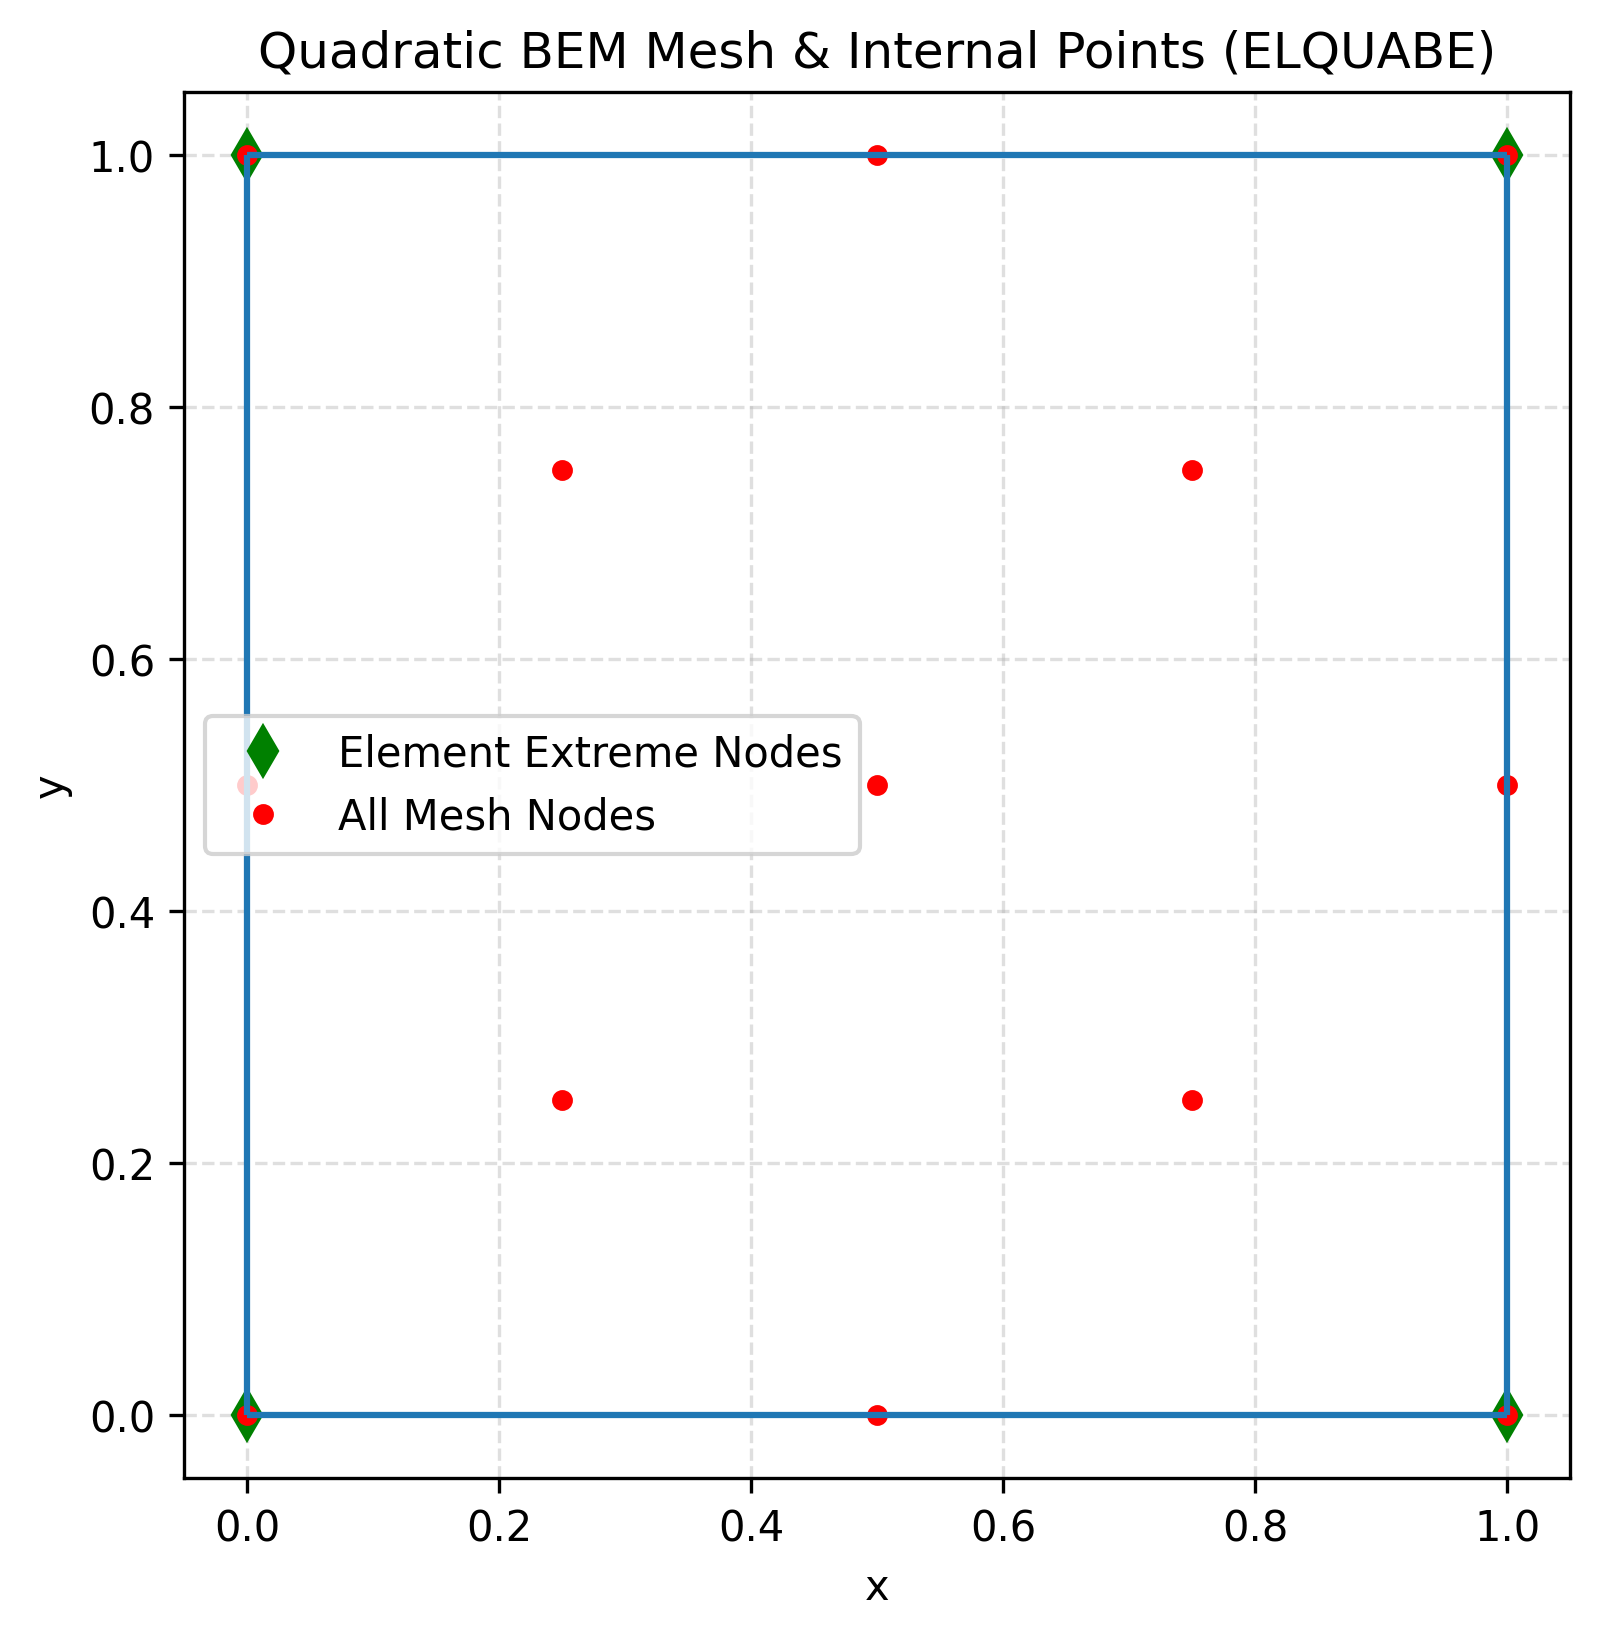

In [12]:
!python preproc.py
from IPython.display import Image, display
display(Image('geometry.png', width=500))

In [13]:
!cat eq12cb.dat

SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)
 4,5,        0.5,0.00
  0.  0.  0.5  0.  1.  0.  1.  0.5  1.  1.  0.5  1.  0.  1.  0.  0.5
 1 2 3
 3 4 5
 5 6 7
 7 8 1
0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 0 0.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
1 0.0 1 1.0 1 0.0 1 1.0 1 0.0 1 1.0 
1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 1 0.0 
 0.5  0.5 0.8  0.2 0.2  0.2 0.2  0.8 0.8  0.8


## 6. Run the Modernized BEM Solver (./elquabe_modern.exe)


In [14]:
!./elquabe_modern.exe
!cat eq12cb.out

 *******************************************************************************
SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)              


  DATA
  NUMBER OF BOUNDARY ELEMENTS=  4
  NUMBER OF INTERNAL POINTS=  5
  SHEAR MODULUS= 0.5000000E+00
  POISSON RATIO= 0.0000000E+00


  BOUNDARY NODES COORDINATES


    NODE          X                  Y

       1      0.0000000E+00      0.0000000E+00
       2      0.5000000E+00      0.0000000E+00
       3      0.1000000E+01      0.0000000E+00
       4      0.1000000E+01      0.5000000E+00
       5      0.1000000E+01      0.1000000E+01
       6      0.5000000E+00      0.1000000E+01
       7      0.0000000E+00      0.1000000E+01
       8      0.0000000E+00      0.5000000E+00


  ELEMENT CONNECTIVITY

    ELE      NODE 1      NODE 2      NODE 3

      1           1           2           3
      2           3           4           5
      3           5           6           7
      4           7           8           1


  B

## 7. Post-Processing, Analytical Validation & von Mises Contour Plot (posproc.py)


In [15]:
%%writefile posproc.py
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib import cm
import meshio

from preproc import input_data, compute_inodes


def read_elquabe_input(filename='eq12cb.dat'):
    """
    Reads the ELQUABE input file (`eq12cb.dat`) and returns material properties,
    boundary node coordinates, element connectivity (`conec`), and internal
    point coordinates.
    """
    with open(filename, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]

    title = lines[0]
    params = lines[1].replace(',', ' ').split()
    ne = int(params[0])
    n_int = int(params[1])
    ge = float(params[2])
    xnu = float(params[3])

    n_bou = 2 * ne
    bou_vals = [float(v) for v in lines[2].split()]
    bou_coords = np.array(bou_vals, dtype=np.float64).reshape((n_bou, 2))

    # Read element connectivity matrix (ne lines: NO1 NO2 NO3)
    conec = np.zeros((ne, 3), dtype=np.int64)
    for i in range(ne):
        conec[i, :] = [int(v) for v in lines[3 + i].split()[:3]]

    int_coords = np.zeros((n_int, 2), dtype=np.float64)
    if n_int > 0:
        int_vals = [float(v) for v in lines[3 + 2 * ne].split()]
        int_coords = np.array(int_vals, dtype=np.float64).reshape((n_int, 2))

    return {
        'title': title,
        'ne': ne,
        'n_bou': n_bou,
        'n_int': n_int,
        'ge': ge,
        'xnu': xnu,
        'bou_coords': bou_coords,
        'conec': conec,
        'int_coords': int_coords,
    }


def read_elquabe_outputs():
    """
    Reads numerical results exported by ELQUABE:
      - `dpbou.dat`: Boundary displacements (ux, uy, |u|)
      - `dpint.dat`: Internal displacements (ux, uy, |u|)
      - `stbou.dat`: Boundary stresses (sigma_x, tau_xy, sigma_y, sigma_vm)
      - `stint.dat`: Internal stresses (sigma_x, tau_xy, sigma_y, sigma_vm)
    """
    dpbou = np.loadtxt('dpbou.dat')
    dpint = np.loadtxt('dpint.dat')
    stbou = np.loadtxt('stbou.dat')
    stint = np.loadtxt('stint.dat')
    return {
        'dpbou': dpbou,
        'dpint': dpint,
        'stbou': stbou,
        'stint': stint,
    }


def compute_analytical_solution(coords, ge, xnu, traction_y=1.0):
    """
    Computes the analytical 2D plane-strain elastostatic solution for a plate
    fixed at y = 0 and subjected to uniform vertical traction sigma_y = traction_y
    at the top edge:
        E' = 2 * G / (1 - nu)
        u_y(y) = (traction_y / E') * y
        sigma_x = 0, tau_xy = 0, sigma_y = traction_y, sigma_vm = |traction_y|
    """
    e_plane_strain = 2.0 * ge / (1.0 - xnu)
    y = coords[:, 1]
    uy_exact = (traction_y / e_plane_strain) * y
    sigma_y_exact = np.full_like(y, traction_y)
    sigma_x_exact = np.zeros_like(y)
    tau_xy_exact = np.zeros_like(y)
    sigma_vm_exact = np.full_like(y, np.abs(traction_y))
    return {
        'uy': uy_exact,
        'sigma_x': sigma_x_exact,
        'tau_xy': tau_xy_exact,
        'sigma_y': sigma_y_exact,
        'sigma_vm': sigma_vm_exact,
    }


def plot_validation(inp, out, save_path='result_plot.png'):
    """
    Compares numerical BEM displacements and stresses (including boundary stresses
    and von Mises equivalent stress) against the analytical 2D elastostatic solution
    and saves the plot to `result_plot.png`.
    """
    bou_coords = inp['bou_coords']
    int_coords = inp['int_coords']
    ge = inp['ge']
    xnu = inp['xnu']

    dpbou = out['dpbou']
    dpint = out['dpint']
    stbou = out['stbou']
    stint = out['stint']

    y_cont = np.linspace(0.0, np.max(bou_coords[:, 1]), 100)
    cont_coords = np.column_stack([np.full_like(y_cont, 0.5), y_cont])
    exact_cont = compute_analytical_solution(cont_coords, ge, xnu, traction_y=1.0)

    exact_bou = compute_analytical_solution(bou_coords, ge, xnu, traction_y=1.0)
    exact_int = compute_analytical_solution(int_coords, ge, xnu, traction_y=1.0)

    # Compute relative L2 errors across all nodes (boundary + internal)
    all_uy_num = np.concatenate([dpbou[:, 1], dpint[:, 1]])
    all_uy_ex = np.concatenate([exact_bou['uy'], exact_int['uy']])
    err_uy = np.linalg.norm(all_uy_num - all_uy_ex) / np.linalg.norm(all_uy_ex)

    all_vm_num = np.concatenate([stbou[:, 3], stint[:, 3]])
    all_vm_ex = np.concatenate([exact_bou['sigma_vm'], exact_int['sigma_vm']])
    err_vm = np.linalg.norm(all_vm_num - all_vm_ex) / np.linalg.norm(all_vm_ex)

    print("=" * 78)
    print("ELQUABE 2D ELASTOSTATIC VALIDATION SUMMARY")
    print("=" * 78)
    print(f"Relative L2 Error in Vertical Displacement u_y      : {err_uy:.4e}")
    print(f"Relative L2 Error in von Mises Stress (All Nodes)   : {err_vm:.4e}")
    print("-" * 78)
    print("Boundary Nodes von Mises Stress (x, y, sigma_x, tau_xy, sigma_y, sigma_vM):")
    for i in range(inp['n_bou']):
        print(
            f"  Node {i+1} ({bou_coords[i,0]:.2f}, {bou_coords[i,1]:.2f}): "
            f"sx={stbou[i,0]: .2e}, txy={stbou[i,1]: .2e}, "
            f"sy={stbou[i,2]:.6f}, vM={stbou[i,3]:.6f}"
        )
    print("-" * 78)
    print("Internal Points von Mises Stress (x, y, sigma_x, tau_xy, sigma_y, sigma_vM):")
    for k in range(inp['n_int']):
        print(
            f"  Point {k+1} ({int_coords[k,0]:.2f}, {int_coords[k,1]:.2f}): "
            f"sx={stint[k,0]: .2e}, txy={stint[k,1]: .2e}, "
            f"sy={stint[k,2]:.6f}, vM={stint[k,3]:.6f}"
        )
    print("=" * 78)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Left subplot: Vertical displacement u_y vs y
    ax1.plot(y_cont, exact_cont['uy'], 'r-', linewidth=2, label='Analytical Solution $u_y(y)$')
    ax1.plot(bou_coords[:, 1], dpbou[:, 1], 'bo', markersize=7, label='BEM Boundary Nodes')
    ax1.plot(int_coords[:, 1], dpint[:, 1], 'gs', markersize=7, label='BEM Internal Points')
    ax1.set_xlabel('Vertical Coordinate $y$ (m)')
    ax1.set_ylabel('Vertical Displacement $u_y$ (m)')
    ax1.set_title('Vertical Displacement $u_y$ vs. $y$')
    ax1.legend(loc='best')
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Right subplot: Boundary & internal stresses (including von Mises) vs y
    ax2.plot(y_cont, exact_cont['sigma_vm'], 'r-', linewidth=2, label='Analytical $\\sigma_{\\mathrm{vM}} = \\sigma_y = 1.0$')
    ax2.plot(y_cont, exact_cont['sigma_x'], 'k--', linewidth=1.5, label='Analytical $\\sigma_x = \\tau_{xy} = 0.0$')
    ax2.plot(bou_coords[:, 1], stbou[:, 3], 'bo', markersize=7, label='BEM Boundary $\\sigma_{\\mathrm{vM}}$')
    ax2.plot(int_coords[:, 1], stint[:, 3], 'gs', markersize=7, label='BEM Internal $\\sigma_{\\mathrm{vM}}$')
    ax2.plot(int_coords[:, 1], stint[:, 0], 'c^', markersize=6, label='BEM Internal $\\sigma_x$')
    ax2.plot(int_coords[:, 1], stint[:, 1], 'mv', markersize=6, label='BEM Internal $\\tau_{xy}$')
    ax2.set_xlabel('Vertical Coordinate $y$ (m)')
    ax2.set_ylabel('Stress (Pa)')
    ax2.set_title('Boundary & Internal Stresses vs. $y$')
    ax2.set_ylim(-0.2, 1.2)
    ax2.legend(loc='best', fontsize=8.5)
    ax2.grid(True, linestyle='--', alpha=0.5)

    fig.suptitle('ELQUABE 2D Elastostatic Validation: Analytical vs. BEM', fontsize=13)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Validation plot saved to '{save_path}'.")
    plt.close(fig)


def export_vtk_and_contours(
    out,
    vtk_path='resultado_elquabe.vtk',
    disp_png_path='displacement_map.png',
    vm_png_path='von_mises_map.png',
):
    """
    Maps the BEM boundary and internal displacements and stresses (including
    von Mises equivalent stress from column 4 of `stbou.dat` and `stint.dat`)
    onto the Gmsh quadratic triangle mesh (`placa.msh`), exports a VTK file,
    and plots the 2D mesh contour maps for displacement and von Mises stress.
    """
    inp_params = input_data()
    computed_data = compute_inodes(inp_params['file_name'], inp_params['bound_cond'])

    coord = computed_data['coordinates']
    ordered_boundary_nodes = computed_data['ordered_boundary_nodes']
    tri6 = computed_data['triangles']
    int_nodes = computed_data['internal_nodes']

    n_total = coord.shape[0]
    disp_vec = np.zeros((n_total, 3), dtype=np.float64)
    uy_field = np.zeros(n_total, dtype=np.float64)
    sx_field = np.zeros(n_total, dtype=np.float64)
    txy_field = np.zeros(n_total, dtype=np.float64)
    sy_field = np.zeros(n_total, dtype=np.float64)
    vm_field = np.zeros(n_total, dtype=np.float64)

    # Map boundary node displacements (dpbou.dat) and stresses (stbou.dat)
    # using the exact ordered_boundary_nodes list from compute_inodes
    dpbou = out['dpbou']
    stbou = out['stbou']
    for bou_idx, node_id in enumerate(ordered_boundary_nodes):
        disp_vec[node_id, 0] = dpbou[bou_idx, 0]
        disp_vec[node_id, 1] = dpbou[bou_idx, 1]
        uy_field[node_id] = dpbou[bou_idx, 1]

        sx_field[node_id] = stbou[bou_idx, 0]
        txy_field[node_id] = stbou[bou_idx, 1]
        sy_field[node_id] = stbou[bou_idx, 2]
        vm_field[node_id] = stbou[bou_idx, 3]

    # Map internal node displacements (dpint.dat) and stresses (stint.dat)
    dpint = out['dpint']
    stint = out['stint']
    for k, node_id in enumerate(int_nodes):
        disp_vec[node_id, 0] = dpint[k, 0]
        disp_vec[node_id, 1] = dpint[k, 1]
        uy_field[node_id] = dpint[k, 1]

        sx_field[node_id] = stint[k, 0]
        txy_field[node_id] = stint[k, 1]
        sy_field[node_id] = stint[k, 2]
        vm_field[node_id] = stint[k, 3]

    # 1. Export VTK with quadratic triangle6 elements
    cells = [('triangle6', tri6)]
    mesh_out = meshio.Mesh(
        coord,
        cells,
        point_data={
            'Displacement': disp_vec,
            'Displacement_Y': uy_field,
            'Sigma_X': sx_field,
            'Tau_XY': txy_field,
            'Sigma_Y': sy_field,
            'Von_Mises_Stress': vm_field,
        },
    )
    meshio.write(vtk_path, mesh_out)
    print(f"VTK file '{vtk_path}' saved successfully.")

    # 2. Subdivide each 6-node triangle into 4 linear triangles for Matplotlib contour plots
    tri3_list = []
    for t in tri6:
        v0, v1, v2, v3, v4, v5 = t
        tri3_list.append([v0, v3, v5])
        tri3_list.append([v3, v1, v4])
        tri3_list.append([v5, v4, v2])
        tri3_list.append([v3, v4, v5])

    tri3_array = np.array(tri3_list)
    triang = mtri.Triangulation(coord[:, 0], coord[:, 1], tri3_array)

    # 2a. Plot Vertical Displacement Contour Map
    fig1, ax1 = plt.subplots(figsize=(6, 5))
    ax1.triplot(triang, color=(0.0, 0.0, 0.0), linewidth=0.4)
    cf1 = ax1.tricontourf(triang, uy_field, levels=20, cmap=cm.jet)
    fig1.colorbar(cf1, ax=ax1, label='Vertical Displacement $u_y$ (m)')
    ax1.set_title('Vertical Displacement $u_y$ (Quadratic Elements)')
    ax1.set_xlabel('$x$ (m)')
    ax1.set_ylabel('$y$ (m)')
    ax1.set_aspect('equal')
    plt.savefig(disp_png_path, dpi=300, bbox_inches='tight')
    print(f"Displacement contour map '{disp_png_path}' saved successfully.")
    plt.close(fig1)

    # 2b. Plot von Mises Equivalent Stress Contour Map with Mesh Overlay
    fig2, ax2 = plt.subplots(figsize=(6, 5))
    cf2 = ax2.tricontourf(triang, vm_field, levels=20, cmap=cm.jet)
    ax2.triplot(triang, color=(0.0, 0.0, 0.0), linewidth=0.5)
    ax2.plot(coord[:, 0], coord[:, 1], 'ko', markersize=3.5)
    fig2.colorbar(cf2, ax=ax2, label='von Mises Stress $\\sigma_{\\mathrm{vM}}$ (Pa)')
    ax2.set_title('von Mises Equivalent Stress $\\sigma_{\\mathrm{vM}}$ (Quadratic Elements)')
    ax2.set_xlabel('$x$ (m)')
    ax2.set_ylabel('$y$ (m)')
    ax2.set_aspect('equal')
    plt.savefig(vm_png_path, dpi=300, bbox_inches='tight')
    print(f"von Mises contour map '{vm_png_path}' saved successfully.")
    plt.close(fig2)


if __name__ == '__main__':
    inp = read_elquabe_input('eq12cb.dat')
    out = read_elquabe_outputs()
    plot_validation(inp, out, save_path='result_plot.png')
    if os.path.exists('placa.msh') or os.path.exists('placa.geo'):
        export_vtk_and_contours(out)

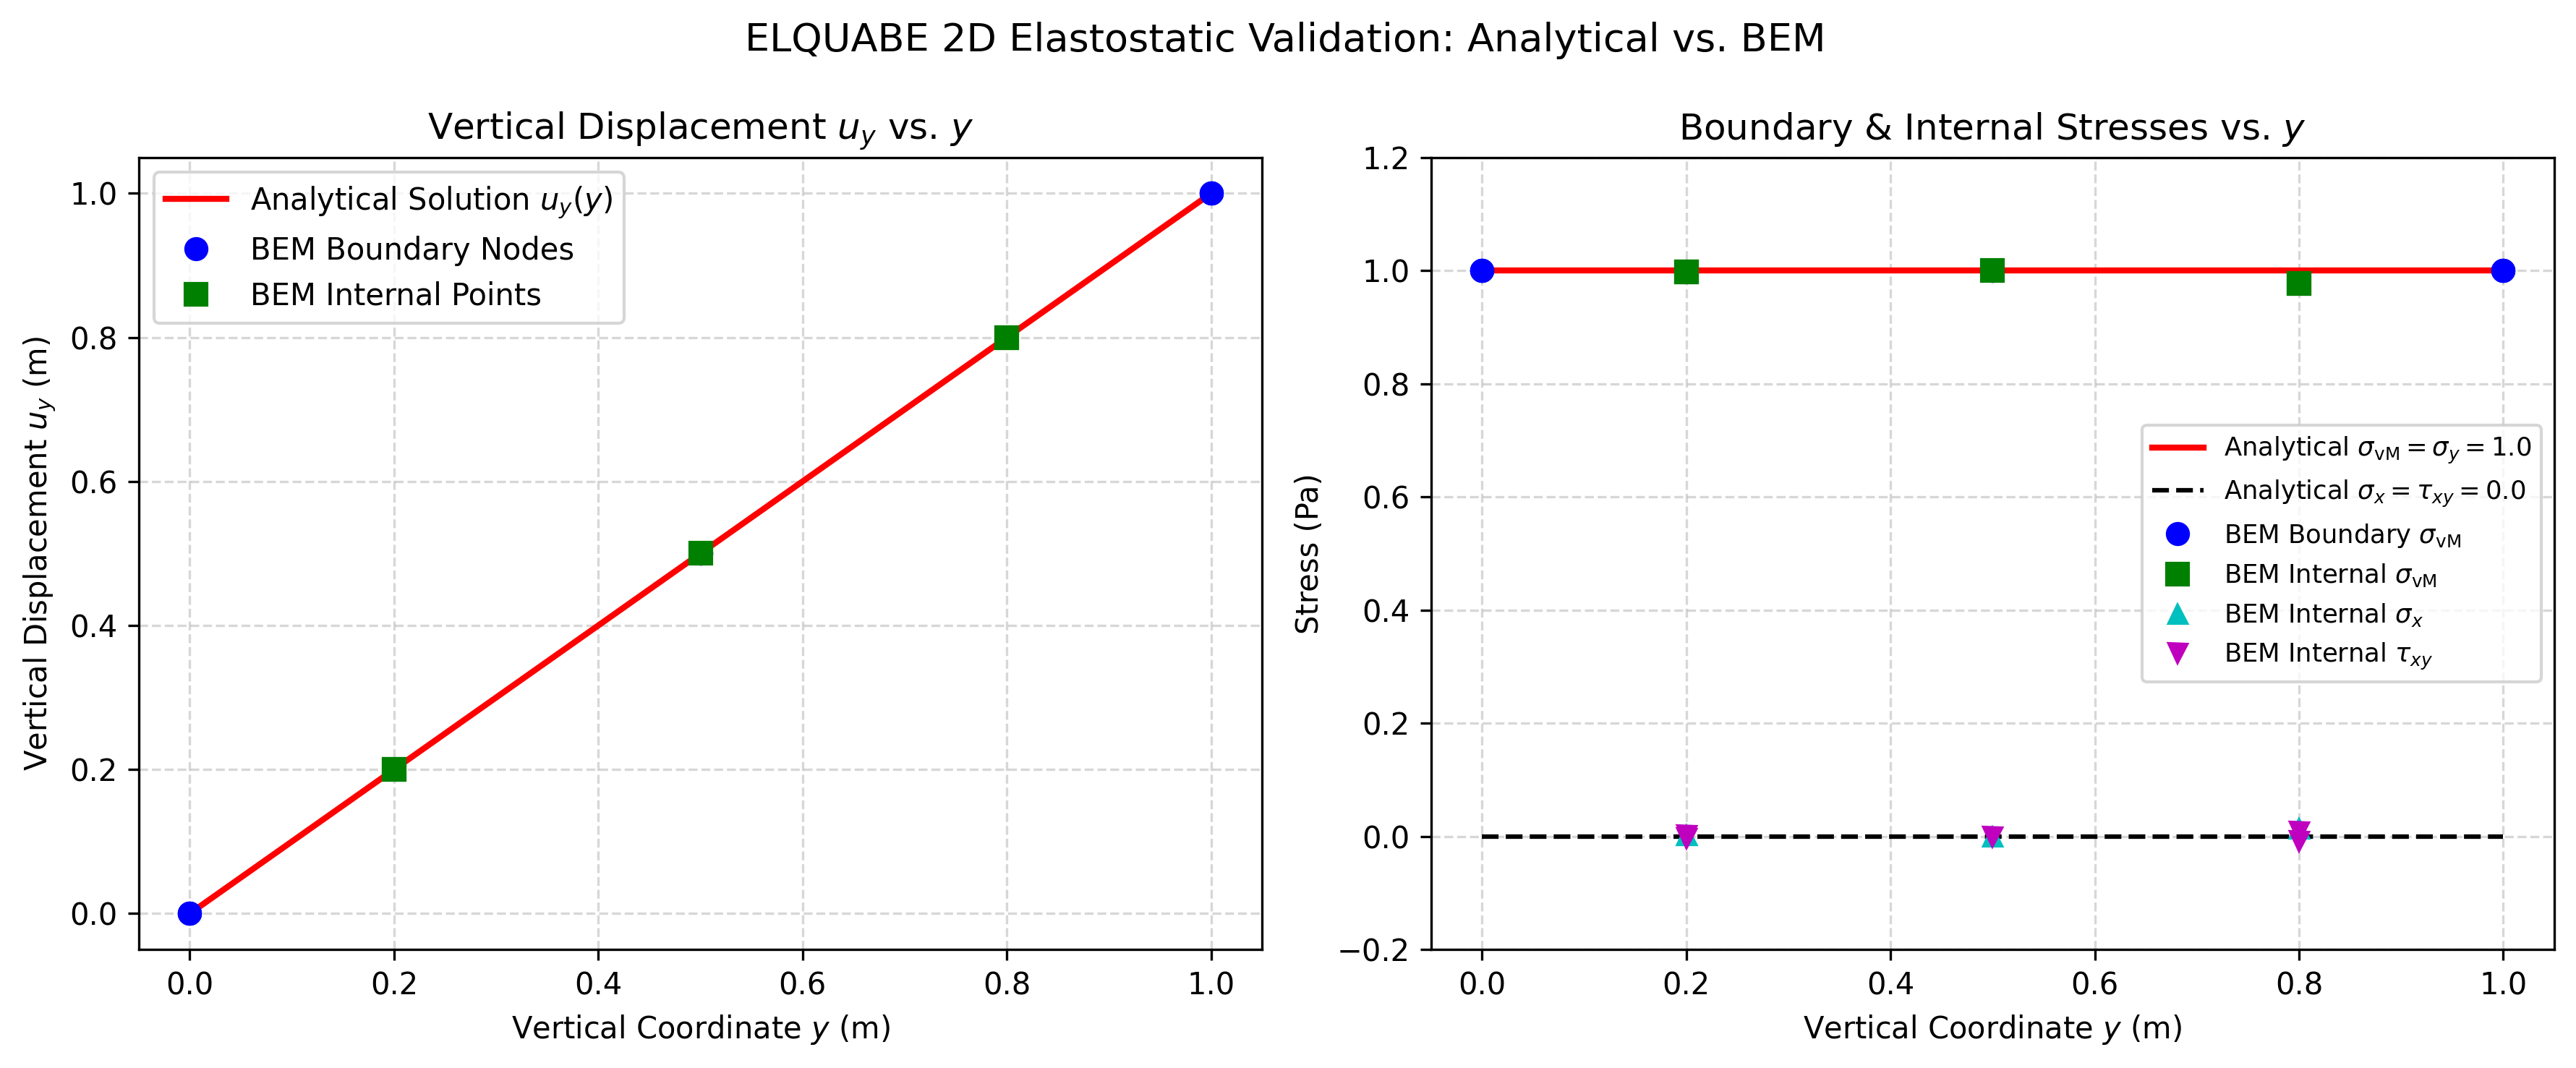

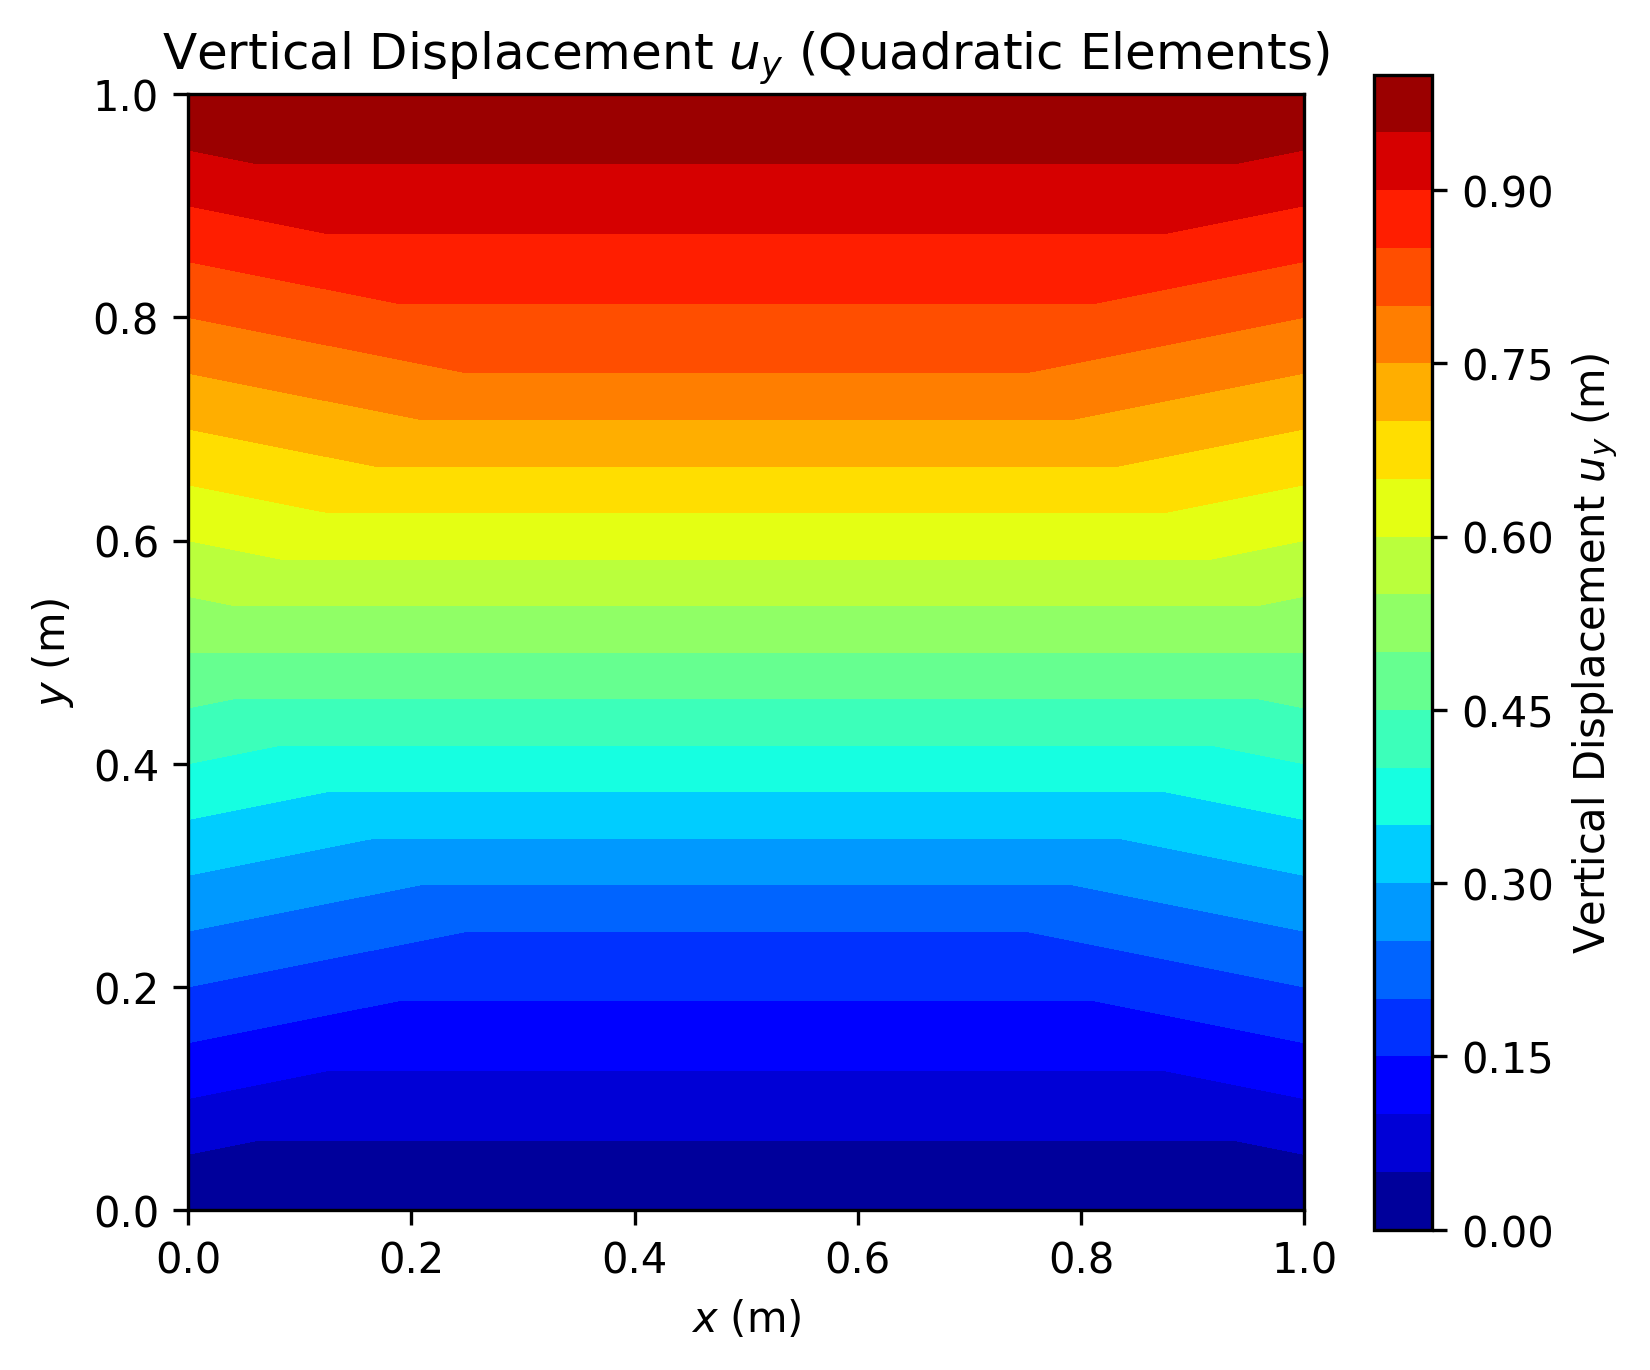

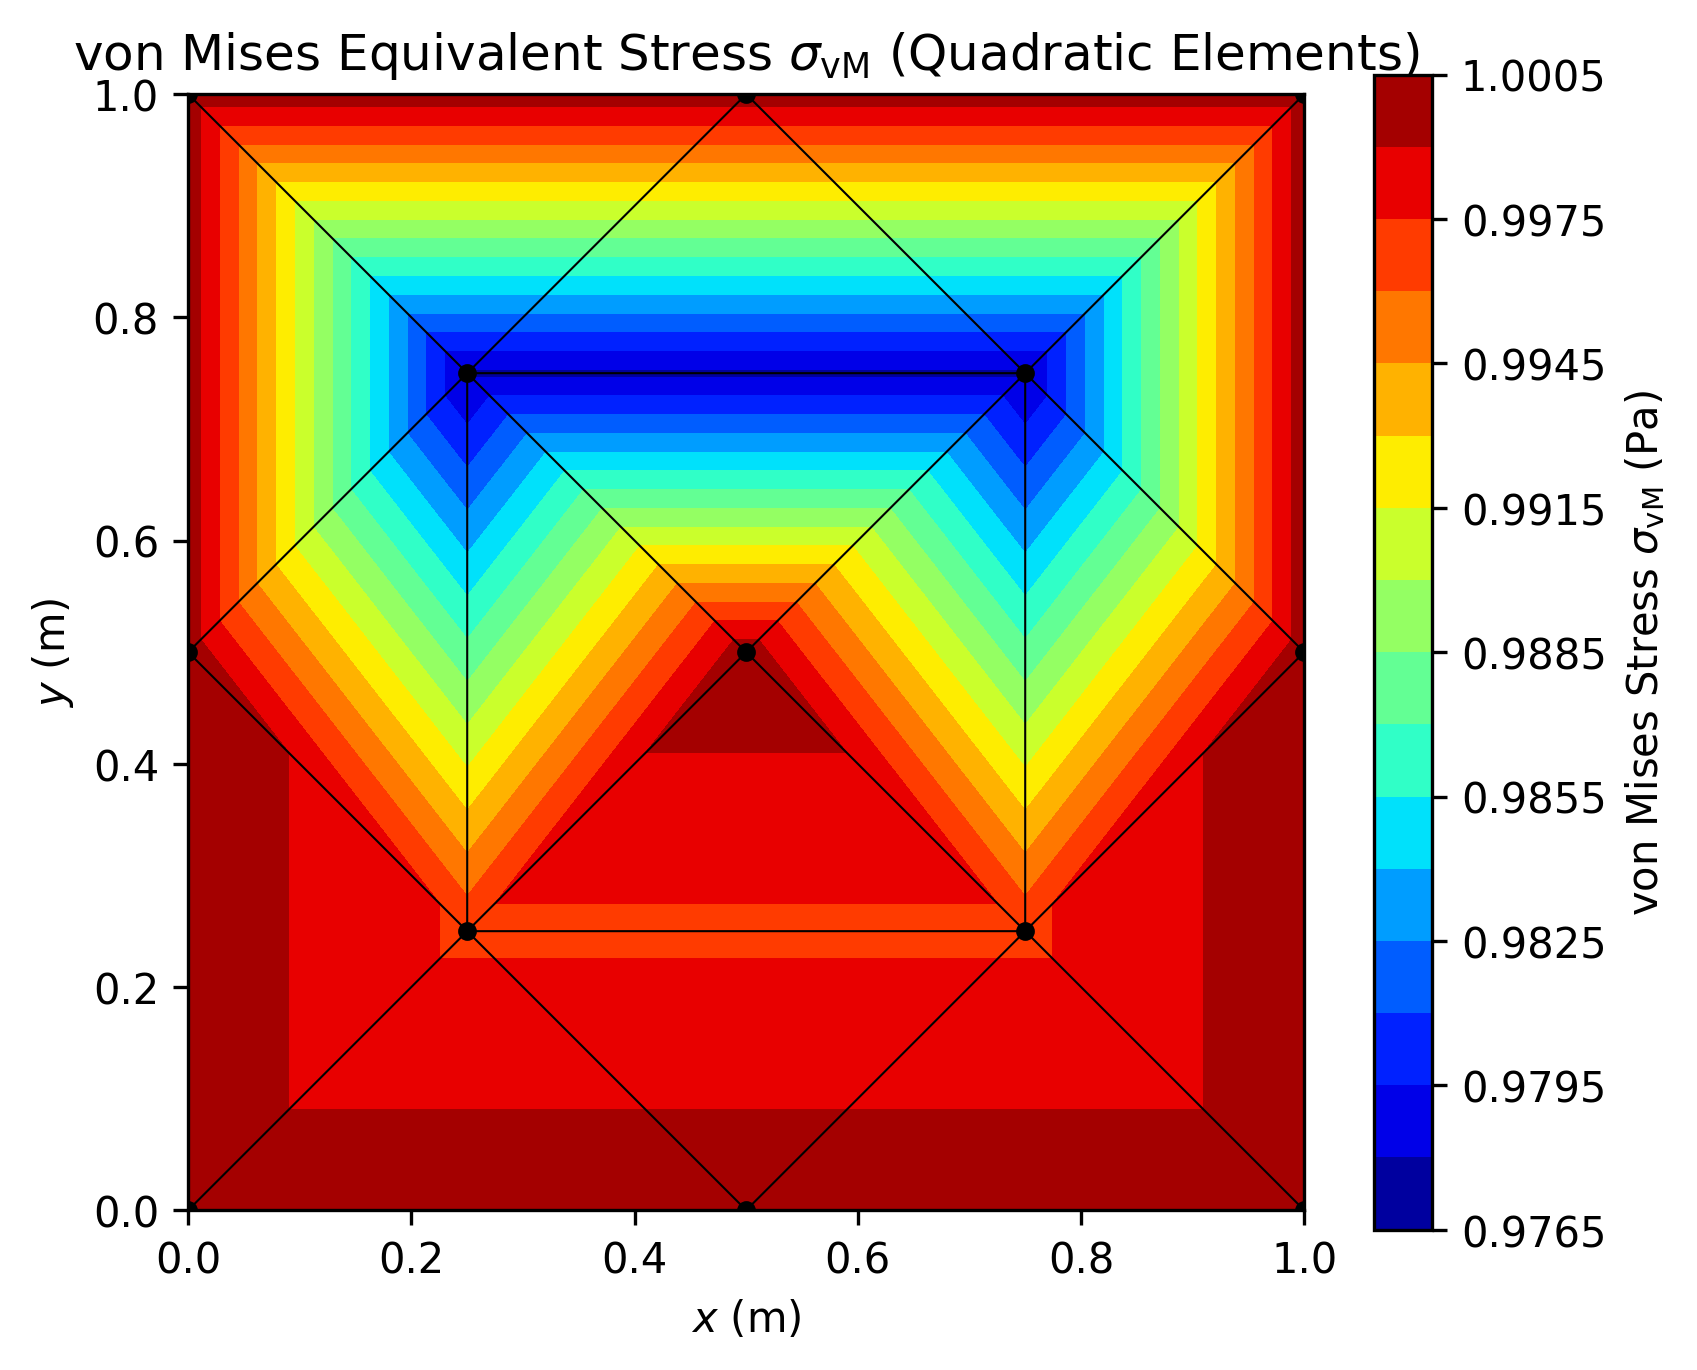

In [16]:
!python posproc.py
from IPython.display import Image, display
display(Image('result_plot.png', width=850))
display(Image('displacement_map.png', width=500))
display(Image('von_mises_map.png', width=500))